In [1]:
# Check that GPU is used
import tensorflow as tf
tf.config.list_physical_devices('GPU')

2025-06-23 12:13:08.298647: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-06-23 12:13:08.546232: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:467] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1750673588.646580   89943 cuda_dnn.cc:8579] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1750673588.700076   89943 cuda_blas.cc:1407] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered
W0000 00:00:1750673589.043954   89943 computation_placer.cc:177] computation placer already registered. Please check linkage and avoid linking 

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]

In [2]:
from PIL import Image
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration des paramètres d'affichage pour de meilleurs graphiques
plt.style.use('seaborn-v0_8')
sns.set_palette("husl")

# Définition des dossiers où sont stockées les données
train_folder = 'chest_xray/train'
test_folder = 'chest_xray/test'
val_folder = 'chest_xray/val'

# Définition des sous-dossiers contenant les images par classe
# NORMAL : radiographies pulmonaires normales
# VIRUS : pneumonie virale
# BACTERIA : pneumonie bactérienne
subfolders = ['NORMAL', 'VIRUS', 'BACTERIA']

# Définition de la taille cible pour le redimensionnement des images
# Réduction à 128x128 pour optimiser les performances d'entraînement
img_width, img_height = 128, 128

print("🏥 Configuration du projet de classification de radiographies pulmonaires")
print(f"📁 Dossier d'entraînement : {train_folder}")
print(f"📁 Dossier de test : {test_folder}")
print(f"📁 Dossier de validation : {val_folder}")
print(f"🔍 Classes à détecter : {subfolders}")
print(f"📐 Taille cible des images : {img_width}x{img_height} pixels")

🏥 Configuration du projet de classification de radiographies pulmonaires
📁 Dossier d'entraînement : chest_xray/train
📁 Dossier de test : chest_xray/test
📁 Dossier de validation : chest_xray/val
🔍 Classes à détecter : ['NORMAL', 'VIRUS', 'BACTERIA']
📐 Taille cible des images : 128x128 pixels


In [3]:
def split_virus_bacteria_pneumonia(folder):
    temp_subfolders = ['NORMAL', 'VIRUS', 'BACTERIA', 'PNEUMONIA']

    # Create the subfolders if they don't exist
    for subfolder in subfolders:
        if not os.path.exists(os.path.join(folder, subfolder)):
            os.makedirs(os.path.join(folder, subfolder))

    # Move the images to the corresponding subfolder
    for subfolder in temp_subfolders:
        subfolder_path = os.path.join(folder, subfolder)
        if subfolder == 'PNEUMONIA':
            for filename in os.listdir(subfolder_path):
                if 'virus' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'VIRUS', filename))
                elif 'bacteria' in filename:
                    os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, 'BACTERIA', filename))
        else:
            for filename in os.listdir(subfolder_path):
                os.rename(os.path.join(subfolder_path, filename), os.path.join(folder, subfolder, filename))

In [4]:
# 📊 ANALYSE STATISTIQUE DU DATASET
print("="*60)
print("📊 ANALYSE STATISTIQUE DU DATASET")
print("="*60)

def analyze_dataset_statistics():
    """
    Analyse complète des statistiques du dataset
    """
    folders = [train_folder, test_folder, val_folder]
    folder_names = ['Entraînement', 'Test', 'Validation']
    
    # Comptage des images par dossier et par classe
    dataset_stats = {}
    
    for folder, name in zip(folders, folder_names):
        dataset_stats[name] = {}
        total_images = 0
        
        print(f"\n📁 Analyse du dossier {name} ({folder}):")
        
        for subfolder in subfolders:
            folder_path = os.path.join(folder, subfolder)
            if os.path.exists(folder_path):
                count = len(os.listdir(folder_path))
                dataset_stats[name][subfolder] = count
                total_images += count
                print(f"   • {subfolder}: {count} images")
            else:
                dataset_stats[name][subfolder] = 0
                print(f"   • {subfolder}: Dossier non trouvé")
        
        dataset_stats[name]['TOTAL'] = total_images
        print(f"   📈 Total: {total_images} images")
    
    return dataset_stats

# Lancement de l'analyse
stats = analyze_dataset_statistics()


📊 ANALYSE STATISTIQUE DU DATASET

📁 Analyse du dossier Entraînement (chest_xray/train):
   • NORMAL: 1341 images
   • VIRUS: 1345 images
   • BACTERIA: 2530 images
   📈 Total: 5216 images

📁 Analyse du dossier Test (chest_xray/test):
   • NORMAL: 234 images
   • VIRUS: 148 images
   • BACTERIA: 242 images
   📈 Total: 624 images

📁 Analyse du dossier Validation (chest_xray/val):
   • NORMAL: 8 images
   • VIRUS: 20 images
   • BACTERIA: 8 images
   📈 Total: 36 images


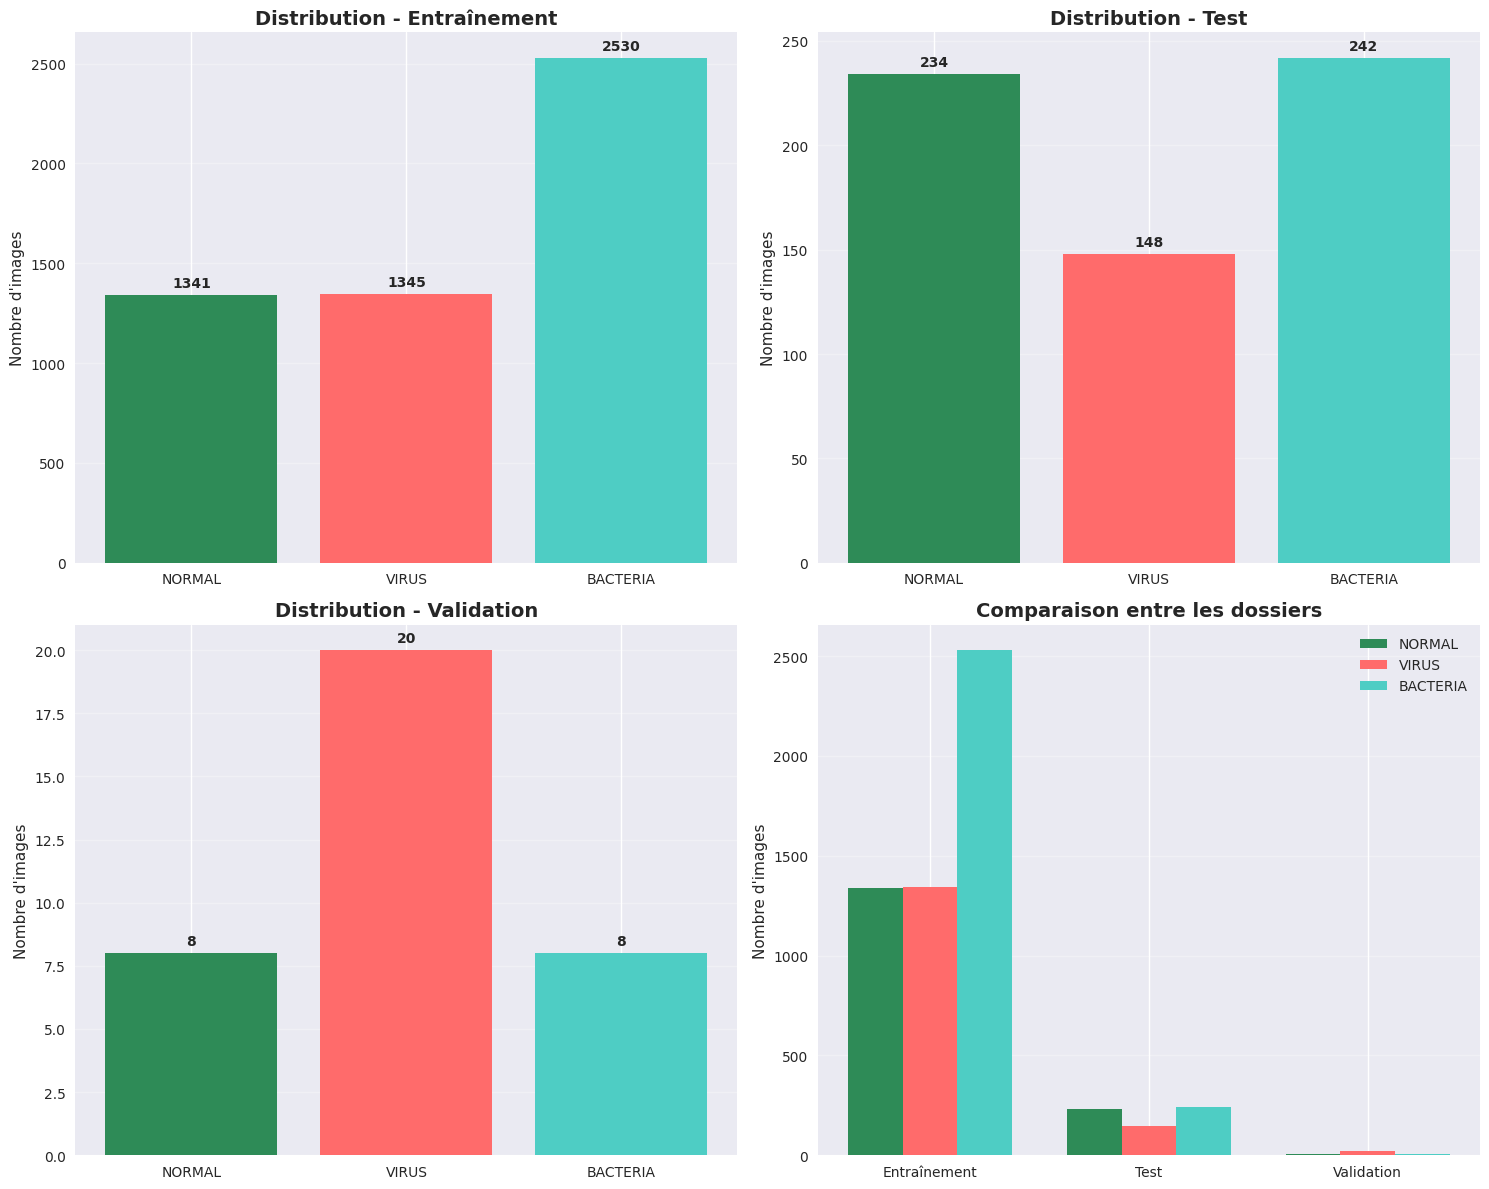

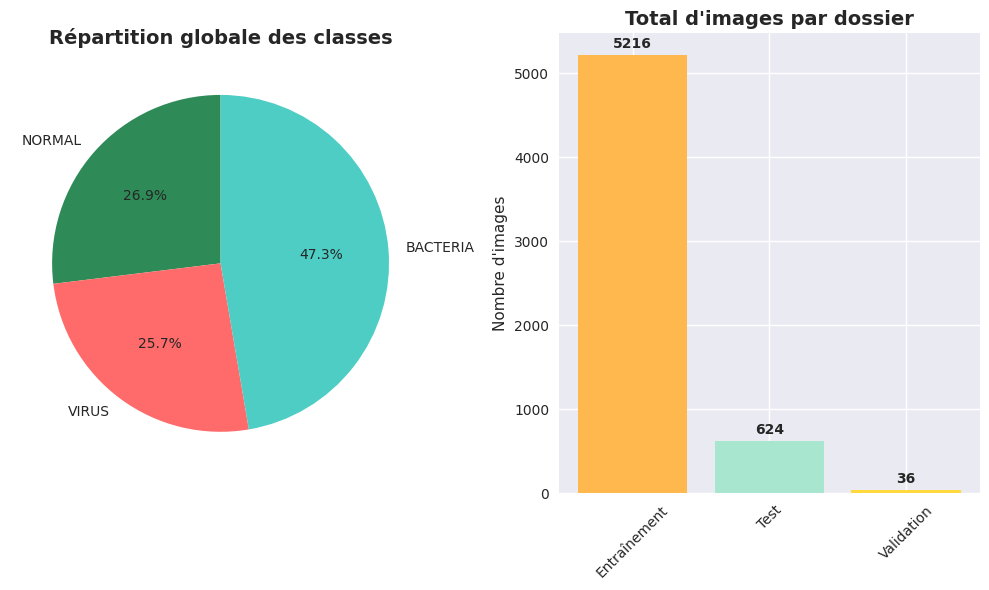


📊 TABLEAU RÉCAPITULATIF DES STATISTIQUES
Dossier         NORMAL     VIRUS      BACTERIA   TOTAL     
------------------------------------------------------------
Entraînement    1341       1345       2530       5216      
Test            234        148        242        624       
Validation      8          20         8          36        
------------------------------------------------------------
TOTAL           1583       1513       2780       5876      

🎯 INSIGHTS:
   • Dataset total: 5,876 images
   • Classe majoritaire: BACTERIA (2,780 images)
   • Classe minoritaire: VIRUS (1,513 images)
   • Ratio déséquilibre: 1.84:1


In [5]:
# 📈 VISUALISATION DES STATISTIQUES DU DATASET

def create_dataset_visualizations(stats):
    """
    Crée des graphiques pour visualiser les statistiques du dataset
    """
    
    # 1. Distribution des classes par dossier
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # Graphique en barres pour chaque dossier
    for i, (folder_name, folder_stats) in enumerate(stats.items()):
        if i < 3:  # Train, Test, Val
            row = i // 2
            col = i % 2
            
            classes = [k for k in folder_stats.keys() if k != 'TOTAL']
            counts = [folder_stats[k] for k in classes]
            
            bars = axes[row, col].bar(classes, counts, 
                                    color=['#2E8B57', '#FF6B6B', '#4ECDC4'])
            axes[row, col].set_title(f'Distribution - {folder_name}', 
                                   fontsize=14, fontweight='bold')
            axes[row, col].set_ylabel('Nombre d\'images')
            axes[row, col].grid(axis='y', alpha=0.3)
            
            # Ajout des valeurs sur les barres
            for bar, count in zip(bars, counts):
                axes[row, col].text(bar.get_x() + bar.get_width()/2, 
                                  bar.get_height() + max(counts)*0.01,
                                  str(count), ha='center', va='bottom', 
                                  fontweight='bold')
    
    # 2. Comparaison globale
    folders = list(stats.keys())
    normal_counts = [stats[f]['NORMAL'] for f in folders]
    virus_counts = [stats[f]['VIRUS'] for f in folders]
    bacteria_counts = [stats[f]['BACTERIA'] for f in folders]
    
    x = np.arange(len(folders))
    width = 0.25
    
    axes[1, 1].bar(x - width, normal_counts, width, label='NORMAL', color='#2E8B57')
    axes[1, 1].bar(x, virus_counts, width, label='VIRUS', color='#FF6B6B')
    axes[1, 1].bar(x + width, bacteria_counts, width, label='BACTERIA', color='#4ECDC4')
    
    axes[1, 1].set_title('Comparaison entre les dossiers', fontsize=14, fontweight='bold')
    axes[1, 1].set_ylabel('Nombre d\'images')
    axes[1, 1].set_xticks(x)
    axes[1, 1].set_xticklabels(folders)
    axes[1, 1].legend()
    axes[1, 1].grid(axis='y', alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 3. Graphique en secteurs pour la répartition globale
    total_stats = {}
    for class_name in subfolders:
        total_stats[class_name] = sum(stats[folder][class_name] for folder in stats.keys())
    
    plt.figure(figsize=(10, 6))
    
    plt.subplot(1, 2, 1)
    colors = ['#2E8B57', '#FF6B6B', '#4ECDC4']
    wedges, texts, autotexts = plt.pie(total_stats.values(), 
                                      labels=total_stats.keys(),
                                      autopct='%1.1f%%',
                                      colors=colors,
                                      startangle=90)
    plt.title('Répartition globale des classes', fontsize=14, fontweight='bold')
    
    # 4. Histogramme des totaux par dossier
    plt.subplot(1, 2, 2)
    folder_totals = [stats[f]['TOTAL'] for f in stats.keys()]
    bars = plt.bar(stats.keys(), folder_totals, color=['#FFB84D', '#A8E6CF', '#FFD93D'])
    plt.title('Total d\'images par dossier', fontsize=14, fontweight='bold')
    plt.ylabel('Nombre d\'images')
    plt.xticks(rotation=45)
    
    # Ajout des valeurs sur les barres
    for bar, total in zip(bars, folder_totals):
        plt.text(bar.get_x() + bar.get_width()/2, 
                bar.get_height() + max(folder_totals)*0.01,
                str(total), ha='center', va='bottom', fontweight='bold')
    
    plt.tight_layout()
    plt.show()
    
    # 5. Tableau récapitulatif
    print("\n📊 TABLEAU RÉCAPITULATIF DES STATISTIQUES")
    print("="*60)
    print(f"{'Dossier':<15} {'NORMAL':<10} {'VIRUS':<10} {'BACTERIA':<10} {'TOTAL':<10}")
    print("-"*60)
    
    grand_total = 0
    for folder_name, folder_stats in stats.items():
        print(f"{folder_name:<15} {folder_stats['NORMAL']:<10} {folder_stats['VIRUS']:<10} {folder_stats['BACTERIA']:<10} {folder_stats['TOTAL']:<10}")
        grand_total += folder_stats['TOTAL']
    
    print("-"*60)
    total_normal = sum(stats[f]['NORMAL'] for f in stats.keys())
    total_virus = sum(stats[f]['VIRUS'] for f in stats.keys())
    total_bacteria = sum(stats[f]['BACTERIA'] for f in stats.keys())
    print(f"{'TOTAL':<15} {total_normal:<10} {total_virus:<10} {total_bacteria:<10} {grand_total:<10}")
    
    print(f"\n🎯 INSIGHTS:")
    print(f"   • Dataset total: {grand_total:,} images")
    print(f"   • Classe majoritaire: {max(total_stats, key=total_stats.get)} ({max(total_stats.values()):,} images)")
    print(f"   • Classe minoritaire: {min(total_stats, key=total_stats.get)} ({min(total_stats.values()):,} images)")
    ratio = max(total_stats.values()) / min(total_stats.values())
    print(f"   • Ratio déséquilibre: {ratio:.2f}:1")

# Création des visualisations
create_dataset_visualizations(stats)


/tmp/ipykernel_89943/2759909921.py:39: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128444 (\N{FRAME WITH PICTURE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


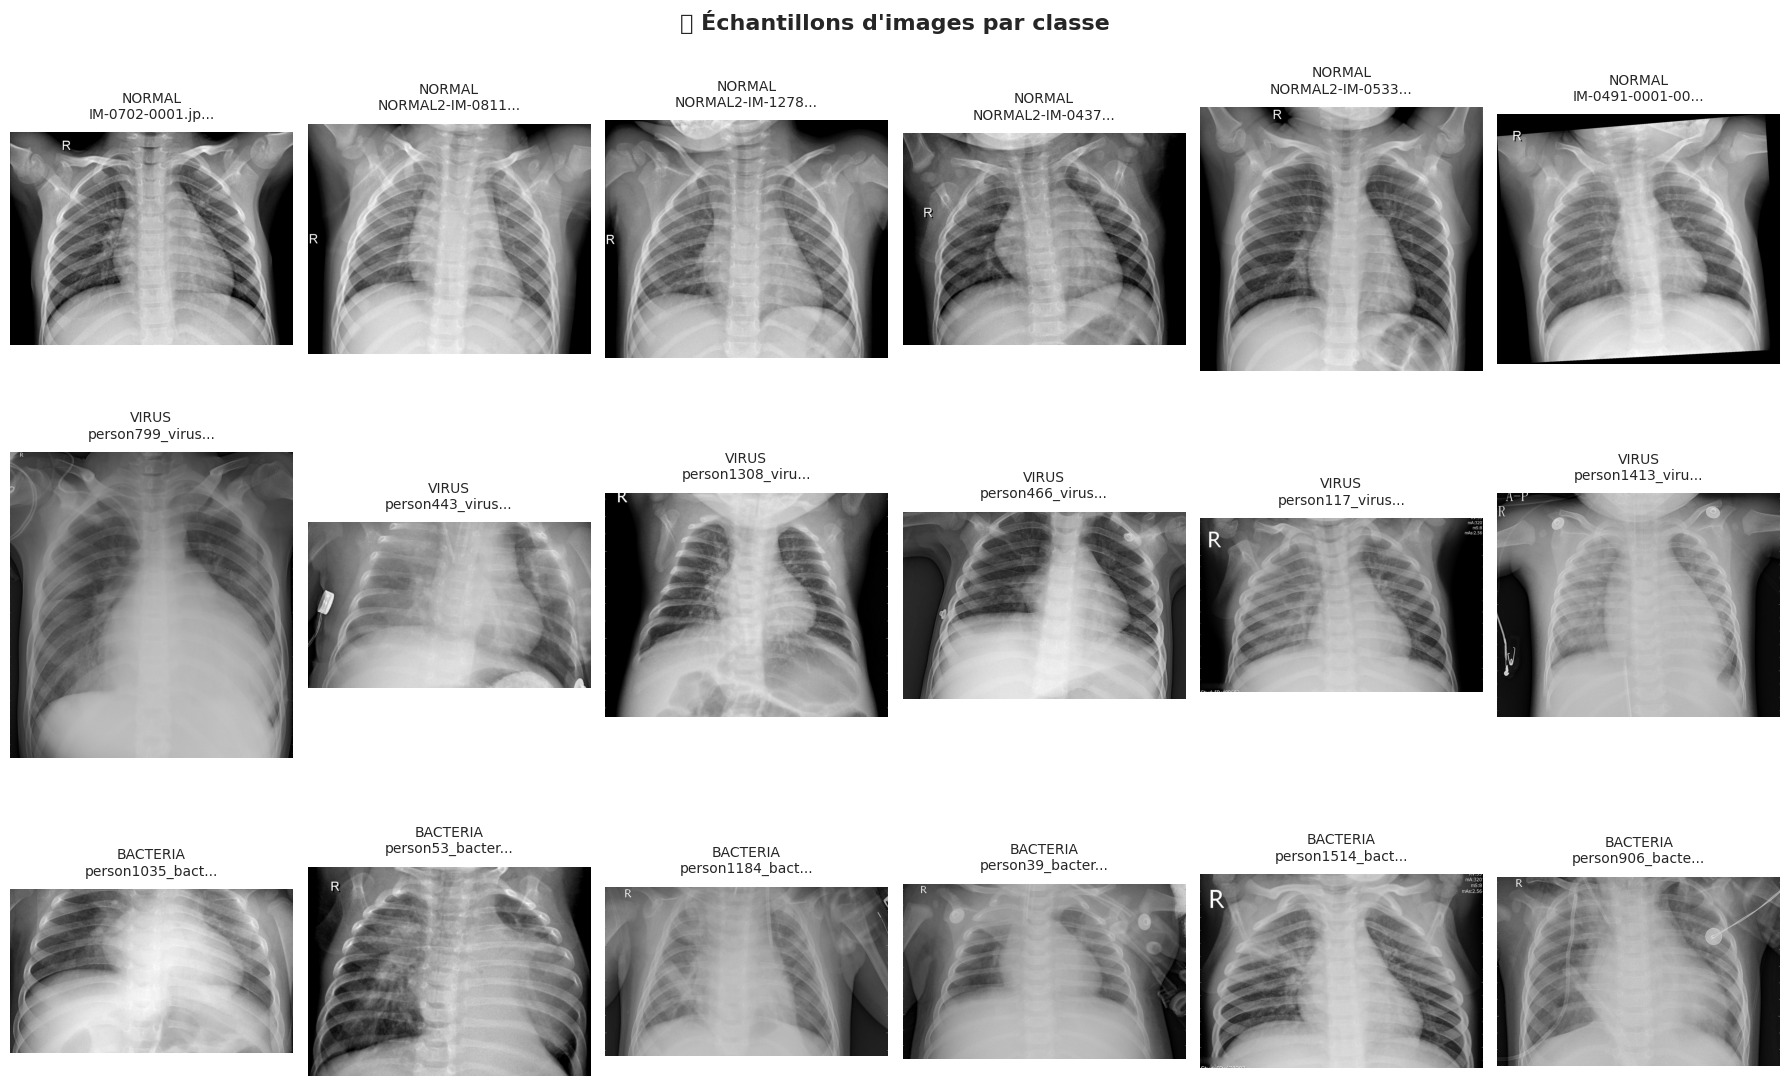

In [6]:
# 🖼️ VISUALISATION D'ÉCHANTILLONS D'IMAGES PAR CLASSE

def display_sample_images():
    """
    Affiche des échantillons d'images pour chaque classe
    """
    fig, axes = plt.subplots(3, 6, figsize=(18, 12))
    
    for i, subfolder in enumerate(subfolders):
        folder_path = os.path.join(train_folder, subfolder)
        
        if os.path.exists(folder_path):
            image_files = os.listdir(folder_path)[:6]  # Prendre les 6 premières images
            
            for j, image_file in enumerate(image_files):
                img_path = os.path.join(folder_path, image_file)
                
                try:
                    # Charger et afficher l'image
                    img = Image.open(img_path)
                    img_gray = img.convert('L')  # Convertir en niveaux de gris
                    
                    axes[i, j].imshow(img_gray, cmap='gray')
                    axes[i, j].set_title(f'{subfolder}\n{image_file[:15]}...', 
                                       fontsize=10, pad=10)
                    axes[i, j].axis('off')
                    
                except Exception as e:
                    axes[i, j].text(0.5, 0.5, f'Erreur:\n{str(e)}', 
                                  ha='center', va='center', transform=axes[i, j].transAxes)
                    axes[i, j].axis('off')
        
        # Ajouter une étiquette pour la classe sur la gauche
        axes[i, 0].set_ylabel(f'Classe: {subfolder}', 
                            fontsize=12, fontweight='bold', rotation=90, 
                            labelpad=20)
    
    plt.suptitle('🖼️ Échantillons d\'images par classe', fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()

# Affichage des échantillons
display_sample_images()


In [7]:
# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(train_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(test_folder)

# Split the pneumonia folder into virus and bacteria subfolders
split_virus_bacteria_pneumonia(val_folder)

In [8]:
# 🔄 FONCTION DE CHARGEMENT ET PRÉPROCESSING DES IMAGES
def load_images_from_folder(folder, limit_per_subfolder=None):
    """
    Charge et préprocesse les images d'un dossier structuré par classes.
    
    Paramètres:
    -----------
    folder : str
        Chemin vers le dossier contenant les sous-dossiers par classe
    limit_per_subfolder : int, optionnel
        Limite le nombre d'images à charger par classe (pour équilibrer le dataset)
    
    Retourne:
    ---------
    X : numpy.ndarray
        Tableau des images préprocessées (normalisées et redimensionnées)
    y : numpy.ndarray
        Tableau des étiquettes correspondantes (encodage numérique)
    """
    X = []  # Stockage des images
    y = []  # Stockage des étiquettes
    
    print(f"📂 Chargement des images depuis: {folder}")
    
    for subfolder in subfolders:
        folder_path = os.path.join(folder, subfolder)
        
        if not os.path.exists(folder_path):
            print(f"⚠️  Dossier manquant: {folder_path}")
            continue
            
        # Sélection des fichiers (avec ou sans limite)
        all_files = os.listdir(folder_path)
        if limit_per_subfolder and len(all_files) > limit_per_subfolder:
            # Sélection aléatoire pour équilibrer les classes
            filenames = np.random.choice(all_files, limit_per_subfolder, replace=False)
            print(f"   🎲 {subfolder}: {limit_per_subfolder} images sélectionnées aléatoirement sur {len(all_files)}")
        else:
            filenames = all_files
            print(f"   ✅ {subfolder}: {len(filenames)} images chargées")
            
        # Traitement de chaque image
        for filename in filenames:
            try:
                img_path = os.path.join(folder_path, filename)
                img = Image.open(img_path)

                # Redimensionnement à la taille cible pour uniformiser les inputs
                img = img.resize((img_width, img_height), Image.Resampling.LANCZOS)

                # Conversion en niveaux de gris pour réduire la complexité
                # (les radiographies sont naturellement en niveaux de gris)
                img = img.convert('L')

                # Conversion en tableau NumPy et ajout à la liste
                img_array = np.array(img)
                X.append(img_array)

                # Attribution de l'étiquette numérique selon l'index de la classe
                # NORMAL=0, VIRUS=1, BACTERIA=2
                y.append(subfolders.index(subfolder))
                
            except Exception as e:
                print(f"⚠️  Erreur lors du chargement de {filename}: {e}")
                continue

    # Conversion en tableaux NumPy pour compatibilité avec TensorFlow/Keras
    X = np.array(X)
    y = np.array(y)
    
    print(f"📊 Dataset chargé: {len(X)} images, forme: {X.shape}")
    print(f"🏷️  Étiquettes: {len(y)} labels, répartition: {np.bincount(y)}")
    
    return X, y

In [9]:
# Generate augmented for the training set
from common.fill_data import generate_augmented_images
generate_augmented_images(train_folder, 'NORMAL', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'BACTERIA', image_size=(img_width, img_height))
generate_augmented_images(train_folder, 'VIRUS', image_size=(img_width, img_height))

Found 1341 images belonging to 1 classes.
Additional count of images to generate: 0
Given NORMAL count: 1341
Augmented NORMAL count: 5000
Found 2530 images belonging to 1 classes.
Additional count of images to generate: 0
Given BACTERIA count: 2530
Augmented BACTERIA count: 5000
Found 1345 images belonging to 1 classes.
Additional count of images to generate: 0
Given VIRUS count: 1345
Augmented VIRUS count: 5000


# 📄 Explication du chargement des données (entraînement, test, validation)

Ce bloc de code charge les images du jeu de données réparti en trois dossiers : `train`, `test` et `val`. Il utilise la fonction `load_images_from_folder` pour prétraiter les images et équilibrer les classes lors du chargement des données d'entraînement.

In [10]:
# Load the training data
# Get min value between the number of normal images and the number of pneumonia images
train_folder = train_folder if train_folder.endswith('_augmented') else f"{train_folder}_augmented"
min_images = min(len(os.listdir(os.path.join(train_folder, subfolders[0]))), len(os.listdir(os.path.join(train_folder, subfolders[1]))), len(os.listdir(os.path.join(train_folder, subfolders[2]))))
X_train, y_train = load_images_from_folder(train_folder, min_images)

# Load the test data
X_test, y_test = load_images_from_folder(test_folder)

# Load the validation data
X_val, y_val = load_images_from_folder(val_folder)

📂 Chargement des images depuis: chest_xray/train_augmented
   ✅ NORMAL: 5000 images chargées
   ✅ VIRUS: 5000 images chargées
   ✅ BACTERIA: 5000 images chargées
📊 Dataset chargé: 15000 images, forme: (15000, 128, 128)
🏷️  Étiquettes: 15000 labels, répartition: [5000 5000 5000]
📂 Chargement des images depuis: chest_xray/test
   ✅ NORMAL: 234 images chargées
   ✅ VIRUS: 148 images chargées
   ✅ BACTERIA: 242 images chargées
📊 Dataset chargé: 624 images, forme: (624, 128, 128)
🏷️  Étiquettes: 624 labels, répartition: [234 148 242]
📂 Chargement des images depuis: chest_xray/val
   ✅ NORMAL: 8 images chargées
   ✅ VIRUS: 20 images chargées
   ✅ BACTERIA: 8 images chargées
📊 Dataset chargé: 36 images, forme: (36, 128, 128)
🏷️  Étiquettes: 36 labels, répartition: [ 8 20  8]


# 📄 Explication : Encodage One-Hot des étiquettes (`labels`)

Ce bloc de code transforme les étiquettes (`y_train`, `y_test`, `y_val`) en vecteurs **one-hot**, format souvent utilisé en apprentissage profond pour les problèmes de classification multiclasse.

In [11]:
# One-hot encode the labels
from tensorflow.keras.utils import to_categorical
y_train = to_categorical(y_train)
y_test = to_categorical(y_test)
y_val = to_categorical(y_val)

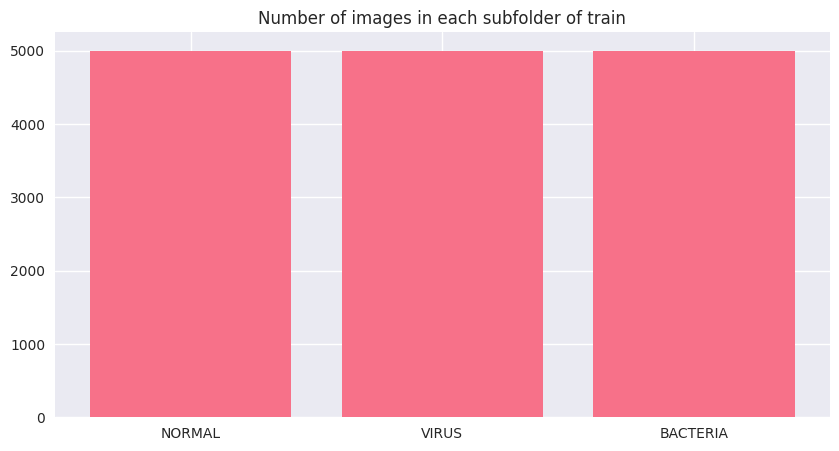

In [12]:
# Make a matplot figure to show how many images are in each subfolder of train
import matplotlib.pyplot as plt
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [len(os.listdir(os.path.join(train_folder, subfolder))) for subfolder in subfolders])
plt.title('Number of images in each subfolder of train')
plt.show()

In [13]:
# 📊 ANALYSE DES DISTRIBUTIONS DE PIXELS PAR CLASSE

def analyze_pixel_distributions(X_data, y_data, dataset_name="Dataset"):
    """
    Analyse les distributions des intensités de pixels pour chaque classe
    """
    print(f"\n🔍 Analyse des distributions de pixels - {dataset_name}")
    
    # Conversion des labels one-hot en labels numériques si nécessaire
    if len(y_data.shape) > 1:
        y_numeric = np.argmax(y_data, axis=1)
    else:
        y_numeric = y_data
    
    # Création des graphiques
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Histogrammes des intensités par classe
    colors = ['#2E8B57', '#FF6B6B', '#4ECDC4']
    
    axes[0, 0].set_title('Distribution des intensités de pixels par classe', 
                        fontsize=12, fontweight='bold')
    
    for i, (subfolder, color) in enumerate(zip(subfolders, colors)):
        class_images = X_data[y_numeric == i]
        if len(class_images) > 0:
            # Calculer l'histogramme pour toutes les images de cette classe
            all_pixels = class_images.flatten()
            axes[0, 0].hist(all_pixels, bins=50, alpha=0.7, label=subfolder, 
                          color=color, density=True)
    
    axes[0, 0].set_xlabel('Intensité des pixels (0-255)')
    axes[0, 0].set_ylabel('Densité')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    # 2. Statistiques descriptives par classe
    stats_data = []
    for i, subfolder in enumerate(subfolders):
        class_images = X_data[y_numeric == i]
        if len(class_images) > 0:
            mean_intensity = np.mean(class_images)
            std_intensity = np.std(class_images)
            min_intensity = np.min(class_images)
            max_intensity = np.max(class_images)
            
            stats_data.append({
                'Classe': subfolder,
                'Moyenne': mean_intensity,
                'Écart-type': std_intensity,
                'Min': min_intensity,
                'Max': max_intensity,
                'Nombre': len(class_images)
            })
    
    # Graphique en barres des moyennes d'intensité
    means = [s['Moyenne'] for s in stats_data]
    stds = [s['Écart-type'] for s in stats_data]
    
    bars = axes[0, 1].bar(subfolders, means, yerr=stds, capsize=5, 
                         color=colors, alpha=0.8)
    axes[0, 1].set_title('Intensité moyenne par classe', fontsize=12, fontweight='bold')
    axes[0, 1].set_ylabel('Intensité moyenne')
    axes[0, 1].grid(axis='y', alpha=0.3)
    
    # Ajout des valeurs sur les barres
    for bar, mean in zip(bars, means):
        axes[0, 1].text(bar.get_x() + bar.get_width()/2, 
                       bar.get_height() + max(means)*0.01,
                       f'{mean:.1f}', ha='center', va='bottom', fontweight='bold')
    
    # 3. Box plot des intensités
    pixel_data_by_class = []
    for i, subfolder in enumerate(subfolders):
        class_images = X_data[y_numeric == i]
        if len(class_images) > 0:
            # Prendre un échantillon pour éviter la surcharge
            sample_size = min(1000, len(class_images))
            sample_indices = np.random.choice(len(class_images), sample_size, replace=False)
            sample_pixels = class_images[sample_indices].flatten()
            pixel_data_by_class.append(sample_pixels)
    
    box_plot = axes[1, 0].boxplot(pixel_data_by_class, labels=subfolders, patch_artist=True)
    for patch, color in zip(box_plot['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[1, 0].set_title('Distribution des intensités (Box Plot)', fontsize=12, fontweight='bold')
    axes[1, 0].set_ylabel('Intensité des pixels')
    axes[1, 0].grid(axis='y', alpha=0.3)
    
    # 4. Tableau récapitulatif
    axes[1, 1].axis('tight')
    axes[1, 1].axis('off')
    
    table_data = []
    for stats in stats_data:
        table_data.append([
            stats['Classe'],
            f"{stats['Moyenne']:.1f}",
            f"{stats['Écart-type']:.1f}",
            f"{stats['Min']:.0f}",
            f"{stats['Max']:.0f}",
            f"{stats['Nombre']}"
        ])
    
    table = axes[1, 1].table(cellText=table_data,
                           colLabels=['Classe', 'Moyenne', 'Écart-type', 'Min', 'Max', 'Nombre'],
                           cellLoc='center',
                           loc='center')
    table.auto_set_font_size(False)
    table.set_fontsize(10)
    table.scale(1.2, 1.5)
    
    # Style du tableau
    for i in range(len(subfolders)):
        table[(i+1, 0)].set_facecolor(colors[i])
        table[(i+1, 0)].set_alpha(0.3)
    
    axes[1, 1].set_title('Statistiques descriptives', fontsize=12, fontweight='bold')
    
    plt.suptitle(f'📊 Analyse des pixels - {dataset_name}', 
                fontsize=16, fontweight='bold', y=0.98)
    plt.tight_layout()
    plt.show()
    
    return stats_data

# Note: Cette analyse sera exécutée après le chargement des données


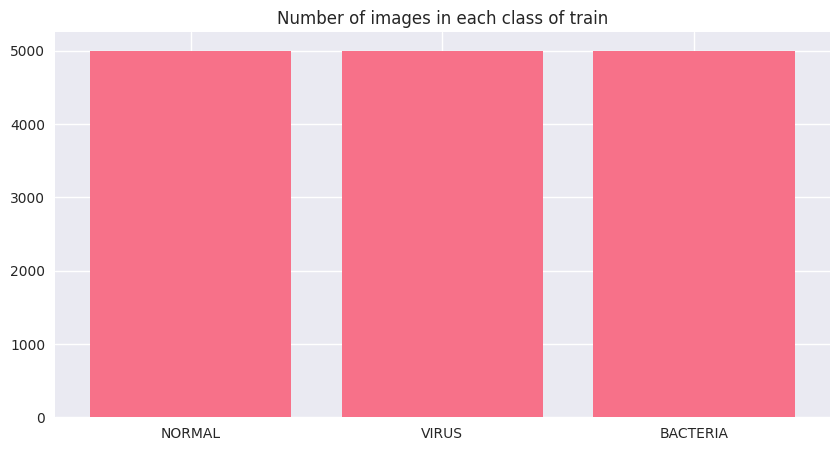

In [14]:
# Make a matplot figure to show how many images if each class in the training set considering it is hot-encoded
plt.figure(figsize=(10, 5))
plt.bar(subfolders, [sum(y_train[:, i]) for i in range(len(subfolders))])
plt.title('Number of images in each class of train')
plt.show()

# 📄 Explication : Normalisation et reshape des images

Ce bloc de code prépare les images (`X_train`, `X_test`, `X_val`) pour l'entraînement d’un modèle de deep learning, en normalisant les pixels et en adaptant la forme des tableaux.

In [15]:
# Normalize the pixel values to be between 0 and 1
X_train = X_train.astype('float32') / 255
X_test = X_test.astype('float32') / 255
X_val = X_val.astype('float32') / 255

X_train = X_train.reshape(len(X_train), img_width, img_height, 1)
X_test = X_test.reshape(len(X_test), img_width, img_height, 1)
X_val = X_val.reshape(len(X_val), img_width, img_height, 1)

📊 Analyse des pixels AVANT normalisation (données brutes 0-255):

🔍 Analyse des distributions de pixels - Données d'entraînement (brutes)


/tmp/ipykernel_89943/2364419874.py:83: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = axes[1, 0].boxplot(pixel_data_by_class, labels=subfolders, patch_artist=True)
/tmp/ipykernel_89943/2364419874.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


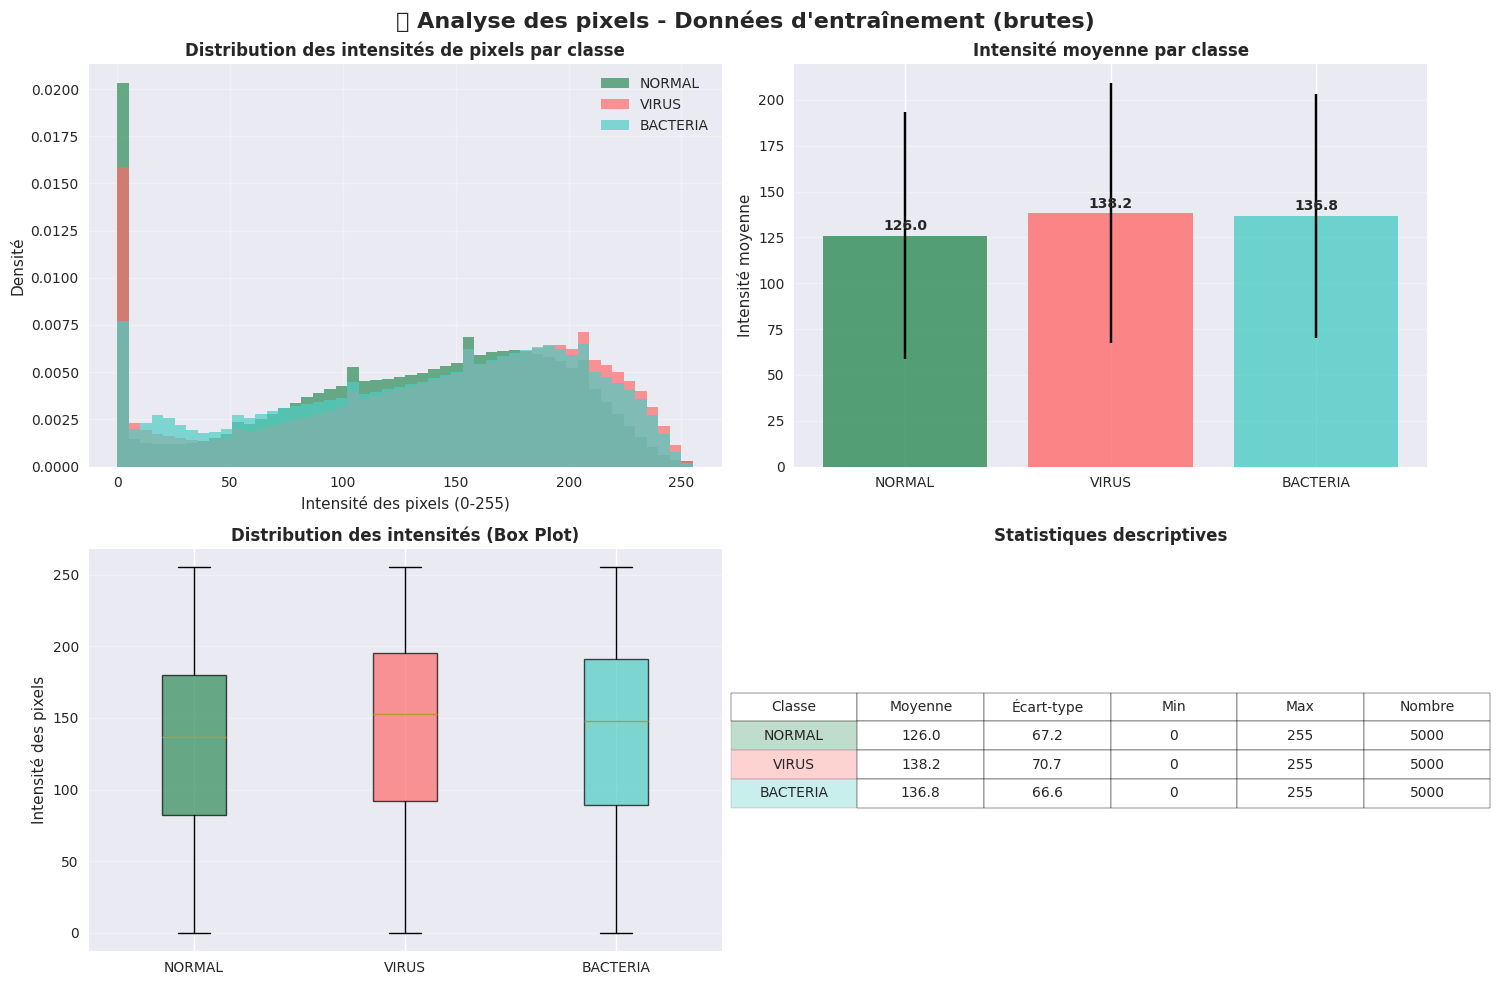


📊 Analyse des pixels APRÈS normalisation (données 0-1):

🔍 Analyse des distributions de pixels - Données d'entraînement (normalisées)


/tmp/ipykernel_89943/2364419874.py:83: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = axes[1, 0].boxplot(pixel_data_by_class, labels=subfolders, patch_artist=True)
/tmp/ipykernel_89943/2364419874.py:124: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


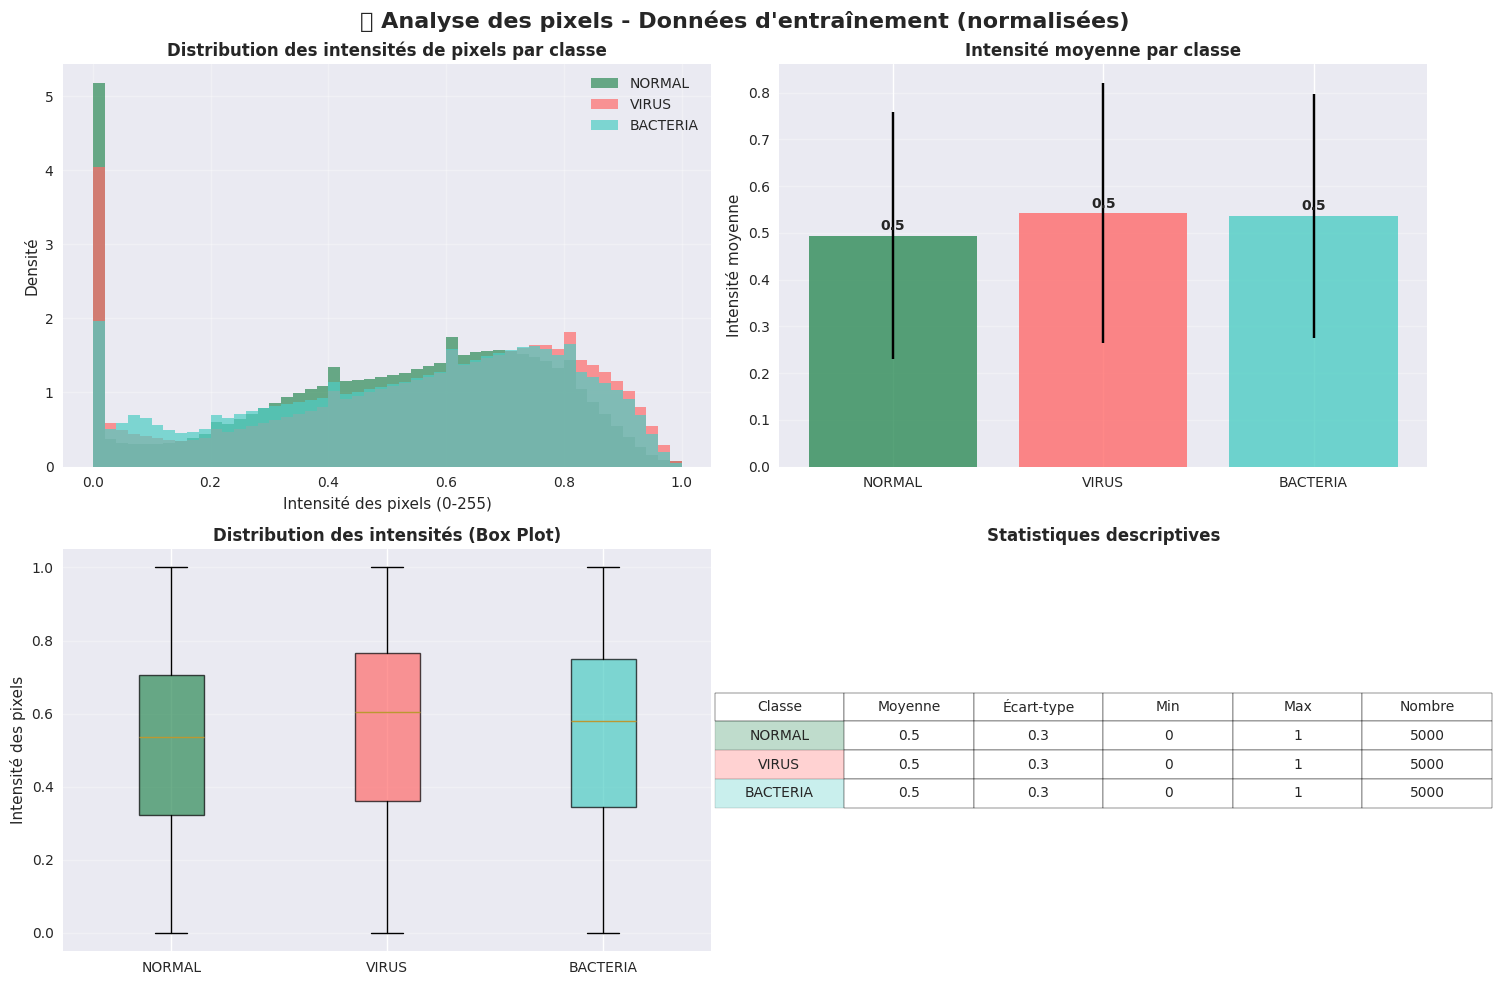


🖼️  Affichage d'un échantillon d'image après préprocessing:
   • Forme de l'image: (128, 128, 1)
   • Type de données: float32
   • Valeurs min/max: 0.000 / 1.000


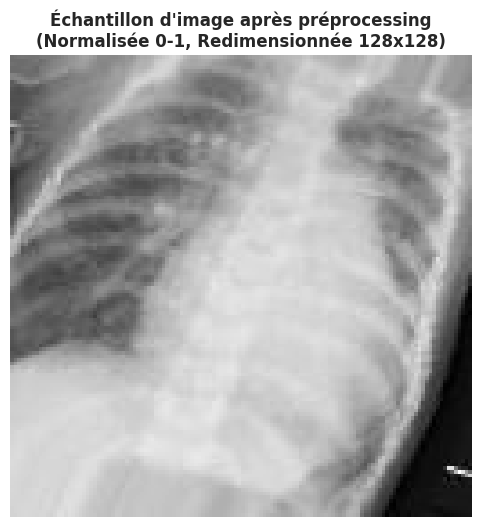

In [16]:
# 🔍 ANALYSE DES DONNÉES APRÈS NORMALISATION

# Analyser les distributions de pixels avant et après normalisation
print("📊 Analyse des pixels AVANT normalisation (données brutes 0-255):")
# Reconvertir temporairement pour l'analyse
X_train_denorm = (X_train * 255).astype('uint8').reshape(X_train.shape[0], img_width, img_height)
analyze_pixel_distributions(X_train_denorm, y_train, "Données d'entraînement (brutes)")

print("\n" + "="*60)
print("📊 Analyse des pixels APRÈS normalisation (données 0-1):")
X_train_for_analysis = X_train.reshape(X_train.shape[0], img_width, img_height)
analyze_pixel_distributions(X_train_for_analysis, y_train, "Données d'entraînement (normalisées)")

# Affichage d'un échantillon d'image
print(f"\n🖼️  Affichage d'un échantillon d'image après préprocessing:")
single_image = X_train[np.random.randint(len(X_train))]
print(f"   • Forme de l'image: {single_image.shape}")
print(f"   • Type de données: {single_image.dtype}")
print(f"   • Valeurs min/max: {single_image.min():.3f} / {single_image.max():.3f}")

plt.figure(figsize=(8, 6))
plt.imshow(single_image.squeeze(), cmap='gray')
plt.title('Échantillon d\'image après préprocessing\n(Normalisée 0-1, Redimensionnée 128x128)', 
          fontsize=12, fontweight='bold')
plt.axis('off')
plt.show()

In [17]:
# Define model metrics
from keras.metrics import AUC

metrics = [
    "accuracy",
    AUC(name='auc')
]

I0000 00:00:1750673616.353357   89943 gpu_device.cc:2019] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3539 MB memory:  -> device: 0, name: NVIDIA RTX 1000 Ada Generation Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


In [18]:
# 🧠 ARCHITECTURE DU MODÈLE CNN (Réseau de Neurones Convolutionnel)

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout

def create_model():
    """
    Crée un modèle CNN pour la classification de radiographies pulmonaires.
    
    Architecture:
    - 4 blocs convolutionnels avec pooling (extraction de caractéristiques)
    - 2 couches denses avec dropout (classification)
    - Couche de sortie avec activation softmax (3 classes)
    
    Retourne:
    ---------
    model : tensorflow.keras.Model
        Modèle CNN compilé et prêt pour l'entraînement
    """
    
    print("🏗️  Construction de l'architecture CNN...")
    
    model = Sequential()

    # 🔸 BLOC CONVOLUTIONNEL 1: Détection des contours de base
    model.add(Conv2D(filters=32,           # 32 filtres de convolution
                     kernel_size=(3,3),    # Taille du filtre 3x3 pixels
                     input_shape=(img_width, img_height, 1),  # Images en niveaux de gris
                     activation="relu"))   # Fonction d'activation ReLU
    model.add(MaxPooling2D(pool_size=(2,2)))  # Réduction de dimensionnalité (division par 2)

    # 🔸 BLOC CONVOLUTIONNEL 2: Détection de motifs plus complexes
    model.add(Conv2D(filters=64, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    # 🔸 BLOC CONVOLUTIONNEL 3: Caractéristiques de niveau intermédiaire
    model.add(Conv2D(filters=128, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    # 🔸 BLOC CONVOLUTIONNEL 4: Caractéristiques de haut niveau
    model.add(Conv2D(filters=256, kernel_size=(3,3), activation="relu"))
    model.add(MaxPooling2D(pool_size=(2,2)))

    # 🔸 APLATISSEMENT: Conversion 2D → 1D pour les couches denses
    model.add(Flatten())

    # 🔸 COUCHES DENSES: Classification basée sur les caractéristiques extraites
    model.add(Dense(256, activation="relu"))    # Couche cachée 1
    model.add(Dropout(0.5))                     # Régularisation (50% de neurones désactivés)

    model.add(Dense(128, activation="relu"))    # Couche cachée 2
    model.add(Dropout(0.5))                     # Régularisation

    # 🔸 COUCHE DE SORTIE: Classification en 3 classes
    model.add(Dense(3, activation="softmax"))   # 3 neurones (NORMAL, VIRUS, BACTERIA)

    # 🔸 COMPILATION DU MODÈLE
    model.compile(
        loss="categorical_crossentropy",        # Fonction de perte pour classification multiclasse
        optimizer="adam",                       # Optimiseur Adam (adaptatif)
        metrics=metrics                         # Métriques d'évaluation (accuracy, AUC)
    )

    print("✅ Modèle CNN créé avec succès!")
    print(f"   • Total des paramètres: {model.count_params():,}")
    
    return model

# Affichage du résumé de l'architecture
model_summary = create_model()
print("\n📋 RÉSUMÉ DE L'ARCHITECTURE:")
model_summary.summary()

/home/atressel/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


🏗️  Construction de l'architecture CNN...
✅ Modèle CNN créé avec succès!
   • Total des paramètres: 2,780,675

📋 RÉSUMÉ DE L'ARCHITECTURE:


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 126, 126, 32)   │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 63, 63, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 61, 61, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 30, 30, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 28, 28, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 14, 14, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 12, 12, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_3 (MaxPooling2D)  │ (None, 6, 6, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 9216)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │     2,359,552 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 3)              │           387 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,780,675 (10.61 MB)

 Trainable params: 2,780,675 (10.61 MB)

 Non-trainable params: 0 (0.00 B)

In [19]:
from tensorflow.keras.callbacks import EarlyStopping
early_stop = EarlyStopping(monitor='loss', patience=3, restore_best_weights=True)

In [20]:
# 🔄 VALIDATION CROISÉE K-FOLD POUR ÉVALUATION ROBUSTE

from sklearn.model_selection import KFold
from tensorflow.keras.preprocessing.image import ImageDataGenerator

print("🎯 Configuration de la validation croisée K-Fold")
print("="*50)

# 🔧 PARAMÈTRES D'ENTRAÎNEMENT
n_splits = 10      # Nombre de plis (folds) pour la validation croisée
epochs = 7         # Nombre d'époques d'entraînement par fold
batch_size = 64    # Taille des lots pour l'entraînement

print(f"📊 Nombre de folds: {n_splits}")
print(f"🔄 Époques par fold: {epochs}")
print(f"📦 Taille des lots: {batch_size}")
print(f"🎲 Graine aléatoire: 42 (reproductibilité)")

# 🎲 INITIALISATION DU K-FOLD
# Le K-Fold divise les données en K parties égales:
# - K-1 parties pour l'entraînement
# - 1 partie pour la validation
# Cette opération est répétée K fois avec une partie différente pour la validation
kf = KFold(n_splits=n_splits, shuffle=True, random_state=42)

# 📊 STOCKAGE DES RÉSULTATS
accuracy_scores = []  # Scores de précision pour chaque fold
histories = []        # Historiques d'entraînement pour chaque fold
models = []          # Modèles entraînés pour chaque fold

print(f"\n🚀 Début de la validation croisée ({n_splits} folds)...")
print("   Chaque fold entraîne un modèle indépendant pour évaluer la robustesse")

# 🔄 BOUCLE DE VALIDATION CROISÉE
fold_number = 1
for train_idx, val_idx in kf.split(X_train, y_train):
    print(f"\n📋 === FOLD {fold_number}/{n_splits} ===")
    
    # 📂 DIVISION DES DONNÉES POUR CE FOLD
    X_train_fold, y_train_fold = X_train[train_idx], y_train[train_idx]
    X_val_fold, y_val_fold = X_train[val_idx], y_train[val_idx]
    
    print(f"   • Données d'entraînement: {len(X_train_fold)} images")
    print(f"   • Données de validation: {len(X_val_fold)} images")

    # 🎨 GÉNÉRATEUR DE DONNÉES (pour l'augmentation en temps réel si nécessaire)
    datagen = ImageDataGenerator()

    # 🔄 CRÉATION DES GÉNÉRATEURS DE DONNÉES
    train_generator = datagen.flow(x=X_train_fold, y=y_train_fold, batch_size=batch_size)
    valid_generator = datagen.flow(x=X_val_fold, y=y_val_fold, batch_size=batch_size)

    # 🧠 CRÉATION ET ENTRAÎNEMENT DU MODÈLE POUR CE FOLD
    print(f"   🏗️  Création du modèle pour le fold {fold_number}...")
    model = create_model()

    # 🚀 ENTRAÎNEMENT DU MODÈLE
    print(f"   🚀 Entraînement en cours ({epochs} époques)...")
    history = model.fit(
        train_generator, 
        validation_data=valid_generator, 
        epochs=epochs, 
        verbose=1,  # Affichage des progress bars
        callbacks=[early_stop]  # Arrêt anticipé si pas d'amélioration
    )
     
    # 📊 STOCKAGE DES RÉSULTATS
    histories.append(history.history)
    models.append(model)
     
    # 📈 AFFICHAGE DES RÉSULTATS DU FOLD
    final_train_acc = history.history['accuracy'][-1]
    final_val_acc = history.history['val_accuracy'][-1]
    final_train_loss = history.history['loss'][-1]
    final_val_loss = history.history['val_loss'][-1]
     
    print(f"   ✅ Fold {fold_number} terminé:")
    print(f"      • Précision finale (train): {final_train_acc:.4f}")
    print(f"      • Précision finale (val): {final_val_acc:.4f}")
    print(f"      • Perte finale (train): {final_train_loss:.4f}")
    print(f"      • Perte finale (val): {final_val_loss:.4f}")
     
    fold_number += 1

print(f"\n🎉 Validation croisée terminée!")
print(f"   • {n_splits} modèles entraînés avec succès")
print(f"   • Prêt pour l'analyse des performances moyennes")


🎯 Configuration de la validation croisée K-Fold
📊 Nombre de folds: 10
🔄 Époques par fold: 7
📦 Taille des lots: 64
🎲 Graine aléatoire: 42 (reproductibilité)

🚀 Début de la validation croisée (10 folds)...
   Chaque fold entraîne un modèle indépendant pour évaluer la robustesse

📋 === FOLD 1/10 ===
   • Données d'entraînement: 13500 images
   • Données de validation: 1500 images
   🏗️  Création du modèle pour le fold 1...
🏗️  Construction de l'architecture CNN...
✅ Modèle CNN créé avec succès!
   • Total des paramètres: 2,780,675
   🚀 Entraînement en cours (7 époques)...
Epoch 1/7


/home/atressel/.local/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()
I0000 00:00:1750673618.739881   90330 service.cc:152] XLA service 0x7f230000fdd0 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1750673618.739915   90330 service.cc:160]   StreamExecutor device (0): NVIDIA RTX 1000 Ada Generation Laptop GPU, Compute Capability 8.9
2025-06-23 12:13:38.797952: I tensorflow/compiler/mlir/tensorflow/utils/dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1750673619.057801   90330 cuda_dnn.cc:529] Loaded cuDNN version 90300


  3/211 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.3116 - auc: 0.4813 - loss: 1.1097 

I0000 00:00:1750673626.147755   90330 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


211/211 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step - accuracy: 0.4202 - auc: 0.6156 - loss: 1.0312

2025-06-23 12:14:01.864483: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 8 bytes spill stores, 8 bytes spill loads

2025-06-23 12:14:02.261531: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 104 bytes spill stores, 104 bytes spill loads

2025-06-23 12:14:05.148752: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_157', 4 bytes spill stores, 4 bytes spill loads



211/211 ━━━━━━━━━━━━━━━━━━━━ 29s 97ms/step - accuracy: 0.4206 - auc: 0.6161 - loss: 1.0307 - val_accuracy: 0.7033 - val_auc: 0.8800 - val_loss: 0.6590
Epoch 2/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 45ms/step - accuracy: 0.6581 - auc: 0.8464 - loss: 0.7308 - val_accuracy: 0.7453 - val_auc: 0.9033 - val_loss: 0.5906
Epoch 3/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.7007 - auc: 0.8747 - loss: 0.6645 - val_accuracy: 0.7440 - val_auc: 0.9077 - val_loss: 0.5699
Epoch 4/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.7299 - auc: 0.8974 - loss: 0.5995 - val_accuracy: 0.7533 - val_auc: 0.9120 - val_loss: 0.5564
Epoch 5/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.7519 - auc: 0.9085 - loss: 0.5669 - val_accuracy: 0.7573 - val_auc: 0.9173 - val_loss: 0.5406
Epoch 6/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/step - accuracy: 0.7598 - auc: 0.9170 - loss: 0.5367 - val_accuracy: 0.7587 - val_auc: 0.9183 - val_loss: 0.5286
Epoch 7/7
211/211 ━━━━━━━━━━━━━━━━━━━━ 9s 44ms/st

In [21]:
# 📊 ANALYSE DES PERFORMANCES DE LA VALIDATION CROISÉE

print("📈 Calcul des métriques moyennes par fold...")

# 📊 EXTRACTION DES MÉTRIQUES POUR CHAQUE FOLD
loss = []        # Perte moyenne d'entraînement par fold
acc = []         # Précision moyenne d'entraînement par fold
val_loss = []    # Perte moyenne de validation par fold
val_acc = []     # Précision moyenne de validation par fold

# Calcul des moyennes pour chaque fold sur toutes les époques
for i, history in enumerate(histories):
    loss.append(np.mean(history["loss"]))
    acc.append(np.mean(history["accuracy"]))
    val_loss.append(np.mean(history["val_loss"]))
    val_acc.append(np.mean(history["val_accuracy"]))
    
    print(f"   Fold {i+1}: Train Acc={acc[i]:.4f}, Val Acc={val_acc[i]:.4f}")

# 🎯 STATISTIQUES GLOBALES
print(f"\n📊 RÉSULTATS GLOBAUX DE LA VALIDATION CROISÉE:")
print(f"   • Précision moyenne (train): {np.mean(acc):.4f} ± {np.std(acc):.4f}")
print(f"   • Précision moyenne (validation): {np.mean(val_acc):.4f} ± {np.std(val_acc):.4f}")
print(f"   • Perte moyenne (train): {np.mean(loss):.4f} ± {np.std(loss):.4f}")
print(f"   • Perte moyenne (validation): {np.mean(val_loss):.4f} ± {np.std(val_loss):.4f}")

# 🎯 DÉTECTION DU SURAPPRENTISSAGE
overfitting_indicator = np.mean(acc) - np.mean(val_acc)
print(f"   • Indicateur de surapprentissage: {overfitting_indicator:.4f}")
if overfitting_indicator > 0.1:
    print("     ⚠️  Surapprentissage détecté (différence > 0.1)")
elif overfitting_indicator > 0.05:
    print("     ⚡ Léger surapprentissage (différence > 0.05)")
else:
    print("     ✅ Pas de surapprentissage significatif")

📈 Calcul des métriques moyennes par fold...
   Fold 1: Train Acc=0.6994, Val Acc=0.7467
   Fold 2: Train Acc=0.6890, Val Acc=0.7223
   Fold 3: Train Acc=0.7142, Val Acc=0.7289
   Fold 4: Train Acc=0.7111, Val Acc=0.7386
   Fold 5: Train Acc=0.6817, Val Acc=0.7603
   Fold 6: Train Acc=0.6787, Val Acc=0.6900
   Fold 7: Train Acc=0.6983, Val Acc=0.7340
   Fold 8: Train Acc=0.6966, Val Acc=0.7224
   Fold 9: Train Acc=0.7155, Val Acc=0.7431
   Fold 10: Train Acc=0.6793, Val Acc=0.6994

📊 RÉSULTATS GLOBAUX DE LA VALIDATION CROISÉE:
   • Précision moyenne (train): 0.6964 ± 0.0134
   • Précision moyenne (validation): 0.7286 ± 0.0202
   • Perte moyenne (train): 0.6508 ± 0.0261
   • Perte moyenne (validation): 0.6037 ± 0.0328
   • Indicateur de surapprentissage: -0.0322
     ✅ Pas de surapprentissage significatif


/home/atressel/.local/lib/python3.10/site-packages/IPython/core/events.py:82: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  func(*args, **kwargs)
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128201 (\N{CHART WITH DOWNWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


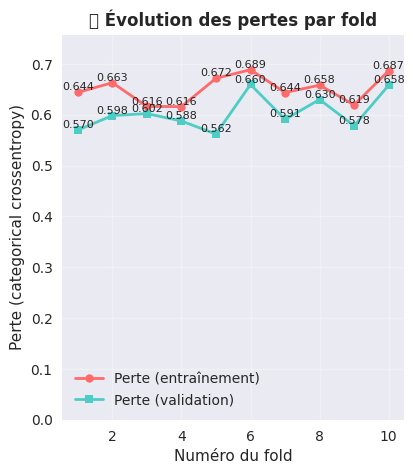

In [22]:
# 📊 VISUALISATION DES PERFORMANCES PAR FOLD

# 1. Graphique des pertes par fold
plt.figure(figsize=(15, 5))

plt.subplot(1, 3, 1)
plt.title('📉 Évolution des pertes par fold', fontsize=12, fontweight='bold')
plt.plot(range(1, len(loss)+1), loss, 'o-', label='Perte (entraînement)', 
         color='#FF6B6B', linewidth=2, markersize=6)
plt.plot(range(1, len(val_loss)+1), val_loss, 's-', label='Perte (validation)', 
         color='#4ECDC4', linewidth=2, markersize=6)
plt.ylim(0.0, max(max(loss), max(val_loss)) * 1.1)
plt.xlabel('Numéro du fold')
plt.ylabel('Perte (categorical crossentropy)')
plt.legend()
plt.grid(alpha=0.3)

# Ajout des valeurs sur les points
for i, (l, vl) in enumerate(zip(loss, val_loss)):
    plt.text(i+1, l, f'{l:.3f}', ha='center', va='bottom', fontsize=8)
    plt.text(i+1, vl, f'{vl:.3f}', ha='center', va='bottom', fontsize=8)

In [23]:
# 🔍 IMPLÉMENTATION DU CLASSIFICATEUR KNN

from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.preprocessing import StandardScaler
import time

print("🚀 Configuration du classificateur K-Nearest Neighbors")
print("="*60)

def prepare_data_for_knn(X_train, X_test, X_val, y_train, y_test, y_val):
    """
    Prépare les données pour l'algorithme KNN en aplatissant les images
    et en normalisant les caractéristiques.
    """
    print("📊 Préparation des données pour KNN...")
    
    # Aplatissement des images (2D -> 1D)
    X_train_flat = X_train.reshape(X_train.shape[0], -1)
    X_test_flat = X_test.reshape(X_test.shape[0], -1)
    X_val_flat = X_val.reshape(X_val.shape[0], -1)
    
    print(f"   • Forme originale: {X_train.shape}")
    print(f"   • Forme aplatie: {X_train_flat.shape}")
    
    # Normalisation des données (importante pour KNN)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train_flat)
    X_test_scaled = scaler.transform(X_test_flat)
    X_val_scaled = scaler.transform(X_val_flat)
    
    # Conversion des labels one-hot en labels numériques
    y_train_numeric = np.argmax(y_train, axis=1) if len(y_train.shape) > 1 else y_train
    y_test_numeric = np.argmax(y_test, axis=1) if len(y_test.shape) > 1 else y_test
    y_val_numeric = np.argmax(y_val, axis=1) if len(y_val.shape) > 1 else y_val
    
    print(f"   • Données d'entraînement: {X_train_scaled.shape[0]} échantillons")
    print(f"   • Données de test: {X_test_scaled.shape[0]} échantillons")
    print(f"   • Données de validation: {X_val_scaled.shape[0]} échantillons")
    
    return (X_train_scaled, X_test_scaled, X_val_scaled, 
            y_train_numeric, y_test_numeric, y_val_numeric, scaler)

def optimize_knn_parameters(X_train, y_train, X_val, y_val):
    """
    Optimise les paramètres K du classificateur KNN
    """
    print("🔧 Optimisation des paramètres KNN...")
    
    # Test de différentes valeurs de K
    k_values = [1, 3, 5, 7, 9, 11, 15, 21]
    validation_scores = []
    training_times = []
    
    print("   Valeurs de K testées:", k_values)
    
    for k in k_values:
        print(f"   • Test avec K={k}...", end=" ")
        
        start_time = time.time()
        knn = KNeighborsClassifier(n_neighbors=k, metric='euclidean', n_jobs=-1)
        knn.fit(X_train, y_train)
        training_time = time.time() - start_time
        
        val_score = knn.score(X_val, y_val)
        validation_scores.append(val_score)
        training_times.append(training_time)
        
        print(f"Score: {val_score:.4f} (temps: {training_time:.2f}s)")
    
    # Trouver le meilleur K
    best_k_idx = np.argmax(validation_scores)
    best_k = k_values[best_k_idx]
    best_score = validation_scores[best_k_idx]
    
    print(f"\n🎯 Meilleur K: {best_k} (score: {best_score:.4f})")
    
    # Visualisation des résultats
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(k_values, validation_scores, 'o-', linewidth=2, markersize=8)
    plt.axvline(x=best_k, color='red', linestyle='--', alpha=0.7, label=f'Meilleur K={best_k}')
    plt.xlabel('Valeur de K')
    plt.ylabel('Score de validation')
    plt.title('Optimisation du paramètre K')
    plt.grid(alpha=0.3)
    plt.legend()
    
    plt.subplot(1, 2, 2)
    plt.plot(k_values, training_times, 's-', linewidth=2, markersize=8, color='orange')
    plt.xlabel('Valeur de K')
    plt.ylabel('Temps d\'entraînement (s)')
    plt.title('Temps d\'entraînement par K')
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return best_k, validation_scores, k_values

# Préparation des données
if 'X_train' in locals() and 'X_test' in locals() and 'X_val' in locals():
    (X_train_knn, X_test_knn, X_val_knn, 
     y_train_knn, y_test_knn, y_val_knn, scaler_knn) = prepare_data_for_knn(
        X_train, X_test, X_val, y_train, y_test, y_val
    )
    
    print("✅ Données préparées avec succès pour KNN!")
else:
    print("❌ Variables de données manquantes. Exécutez d'abord les cellules de chargement des données.")


🚀 Configuration du classificateur K-Nearest Neighbors
📊 Préparation des données pour KNN...
   • Forme originale: (15000, 128, 128, 1)
   • Forme aplatie: (15000, 16384)
   • Données d'entraînement: 15000 échantillons
   • Données de test: 624 échantillons
   • Données de validation: 36 échantillons
✅ Données préparées avec succès pour KNN!


🔧 Optimisation des paramètres KNN...
   Valeurs de K testées: [1, 3, 5, 7, 9, 11, 15, 21]
   • Test avec K=1... Score: 0.3056 (temps: 0.11s)
   • Test avec K=3... Score: 0.2778 (temps: 0.10s)
   • Test avec K=5... Score: 0.2500 (temps: 0.11s)
   • Test avec K=7... Score: 0.2500 (temps: 0.10s)
   • Test avec K=9... Score: 0.2500 (temps: 0.10s)
   • Test avec K=11... Score: 0.3056 (temps: 0.11s)
   • Test avec K=15... Score: 0.3056 (temps: 0.12s)
   • Test avec K=21... Score: 0.3056 (temps: 0.11s)

🎯 Meilleur K: 1 (score: 0.3056)


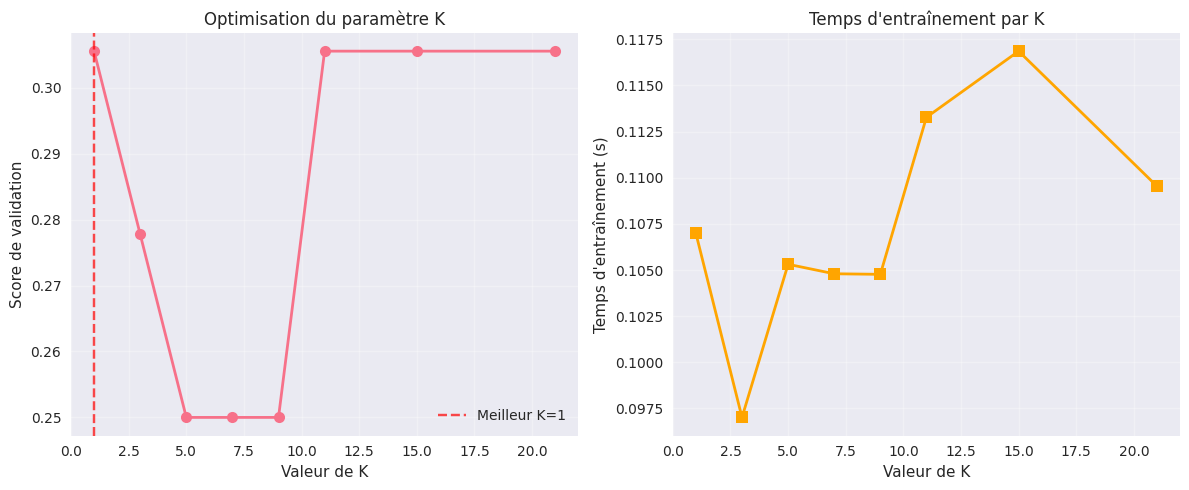


🚀 Entraînement du modèle KNN final...
✅ Modèle KNN entraîné en 0.11 secondes
   • Paramètre K optimal: 1
   • Nombre d'échantillons d'entraînement: 15,000
   • Nombre de caractéristiques: 16,384


In [24]:
# 🎯 ENTRAÎNEMENT ET OPTIMISATION KNN

# Optimisation des paramètres K si les données sont disponibles
if 'X_train_knn' in locals() and 'X_val_knn' in locals():
    best_k, validation_scores, k_values = optimize_knn_parameters(
        X_train_knn, y_train_knn, X_val_knn, y_val_knn
    )
    
    print("\n🚀 Entraînement du modèle KNN final...")
    start_time = time.time()
    
    # Créer et entraîner le modèle final avec le meilleur K
    knn_final = KNeighborsClassifier(
        n_neighbors=best_k, 
        metric='euclidean', 
        n_jobs=-1
    )
    knn_final.fit(X_train_knn, y_train_knn)
    training_time = time.time() - start_time
    
    print(f"✅ Modèle KNN entraîné en {training_time:.2f} secondes")
    print(f"   • Paramètre K optimal: {best_k}")
    print(f"   • Nombre d'échantillons d'entraînement: {len(X_train_knn):,}")
    print(f"   • Nombre de caractéristiques: {X_train_knn.shape[1]:,}")
    
else:
    print("❌ Impossible d'optimiser KNN - données manquantes")


📈 Évaluation des performances KNN...
🎯 RÉSULTATS KNN:
   • Précision sur les données de test: 0.5353 (53.53%)
   • Précision sur les données de validation: 0.3056 (30.56%)
   • Temps de prédiction (test): 5.94 secondes
   • Temps par échantillon: 9.52 ms

📋 RAPPORT DE CLASSIFICATION DÉTAILLÉ:
              precision    recall  f1-score   support

      NORMAL     0.7921    0.3419    0.4776       234
       VIRUS     0.3411    0.5946    0.4335       148
    BACTERIA     0.6264    0.6860    0.6548       242

    accuracy                         0.5353       624
   macro avg     0.5865    0.5408    0.5220       624
weighted avg     0.6209    0.5353    0.5359       624



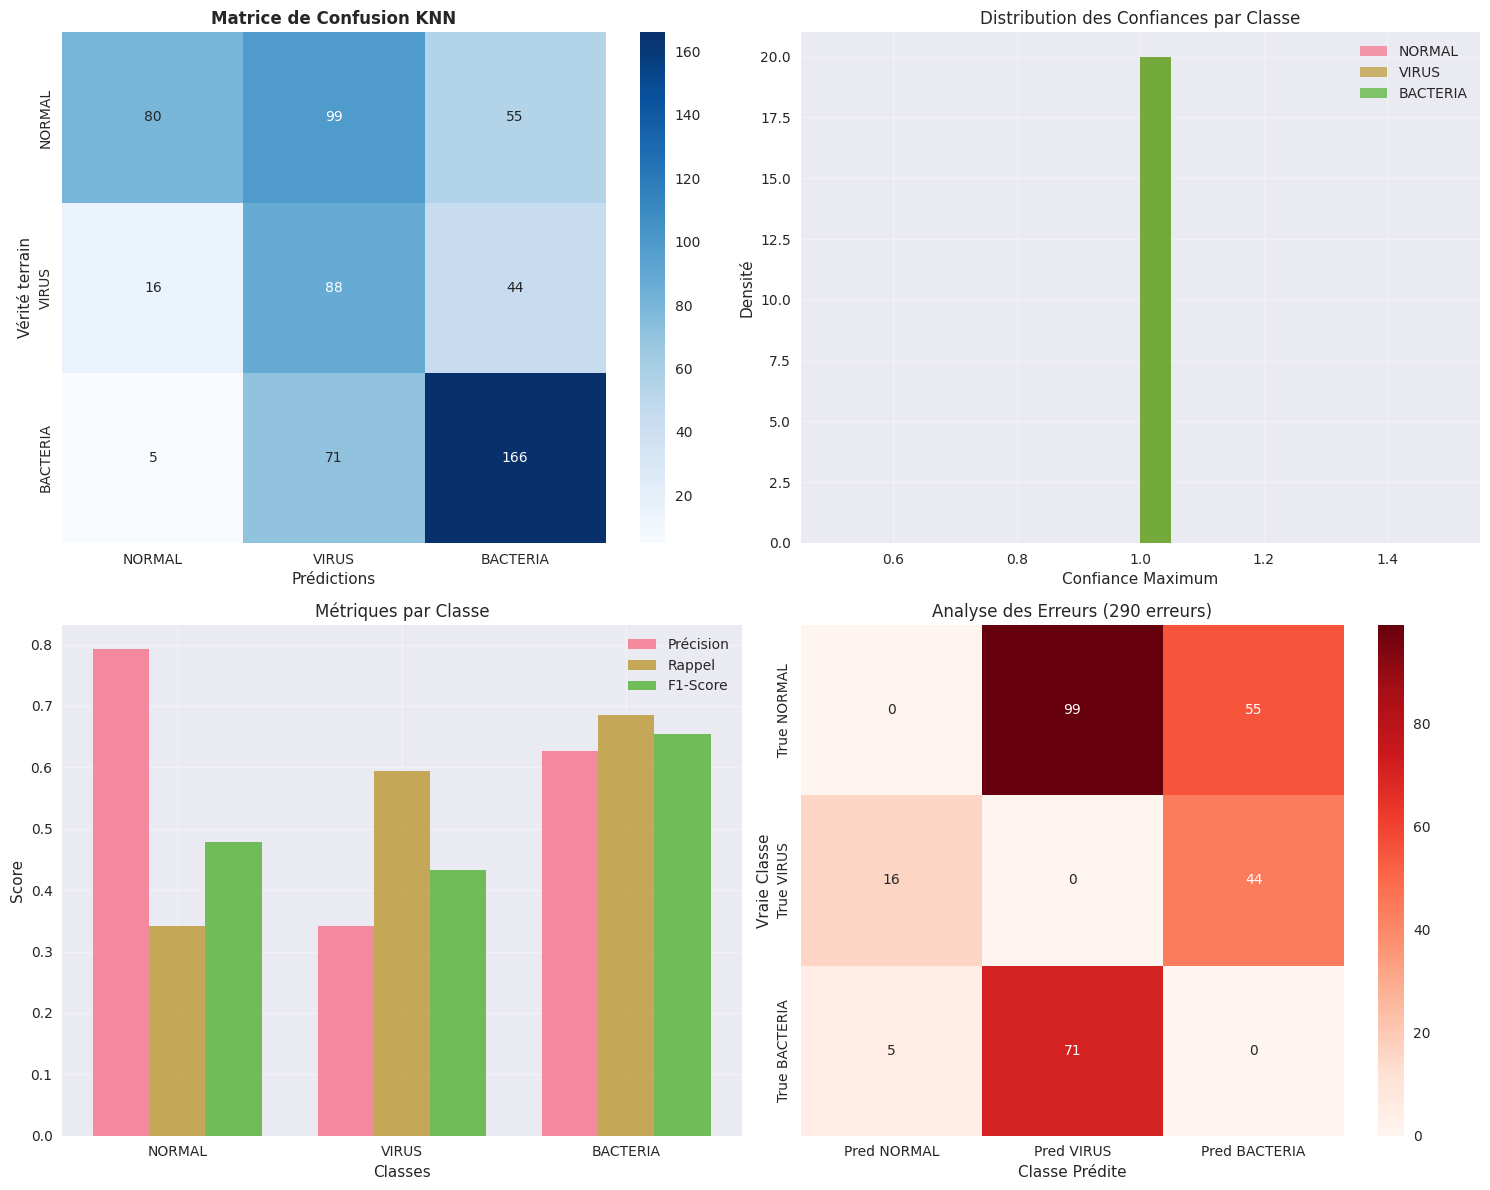

✅ Évaluation KNN terminée!


In [25]:
# 📊 ÉVALUATION DU MODÈLE KNN

def evaluate_knn_model(knn_model, X_test, y_test, X_val, y_val, class_names):
    """
    Évalue les performances du modèle KNN sur les données de test et validation
    """
    print("📈 Évaluation des performances KNN...")
    
    # Prédictions sur les données de test
    start_time = time.time()
    y_pred_test = knn_model.predict(X_test)
    y_pred_proba_test = knn_model.predict_proba(X_test)
    test_prediction_time = time.time() - start_time
    
    # Prédictions sur les données de validation
    y_pred_val = knn_model.predict(X_val)
    
    # Calcul des métriques
    test_accuracy = accuracy_score(y_test, y_pred_test)
    val_accuracy = accuracy_score(y_val, y_pred_val)
    
    print(f"🎯 RÉSULTATS KNN:")
    print(f"   • Précision sur les données de test: {test_accuracy:.4f} ({test_accuracy*100:.2f}%)")
    print(f"   • Précision sur les données de validation: {val_accuracy:.4f} ({val_accuracy*100:.2f}%)")
    print(f"   • Temps de prédiction (test): {test_prediction_time:.2f} secondes")
    print(f"   • Temps par échantillon: {test_prediction_time/len(X_test)*1000:.2f} ms")
    
    # Rapport de classification détaillé
    print(f"\n📋 RAPPORT DE CLASSIFICATION DÉTAILLÉ:")
    print("="*60)
    print(classification_report(y_test, y_pred_test, 
                              target_names=class_names, 
                              digits=4))
    
    # Matrice de confusion
    cm = confusion_matrix(y_test, y_pred_test)
    
    # Visualisation des résultats
    fig, axes = plt.subplots(2, 2, figsize=(15, 12))
    
    # 1. Matrice de confusion
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names,
                ax=axes[0, 0])
    axes[0, 0].set_title('Matrice de Confusion KNN', fontweight='bold')
    axes[0, 0].set_xlabel('Prédictions')
    axes[0, 0].set_ylabel('Vérité terrain')
    
    # 2. Distribution des confiances par classe
    axes[0, 1].set_title('Distribution des Confiances par Classe')
    max_probs = np.max(y_pred_proba_test, axis=1)
    for i, class_name in enumerate(class_names):
        class_mask = y_test == i
        if np.sum(class_mask) > 0:
            class_confidences = max_probs[class_mask]
            axes[0, 1].hist(class_confidences, bins=20, alpha=0.7, 
                           label=class_name, density=True)
    axes[0, 1].set_xlabel('Confiance Maximum')
    axes[0, 1].set_ylabel('Densité')
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)
    
    # 3. Comparaison des métriques par classe
    from sklearn.metrics import precision_recall_fscore_support
    precision, recall, f1, support = precision_recall_fscore_support(
        y_test, y_pred_test, average=None
    )
    
    x_pos = np.arange(len(class_names))
    width = 0.25
    
    axes[1, 0].bar(x_pos - width, precision, width, label='Précision', alpha=0.8)
    axes[1, 0].bar(x_pos, recall, width, label='Rappel', alpha=0.8)
    axes[1, 0].bar(x_pos + width, f1, width, label='F1-Score', alpha=0.8)
    
    axes[1, 0].set_xlabel('Classes')
    axes[1, 0].set_ylabel('Score')
    axes[1, 0].set_title('Métriques par Classe')
    axes[1, 0].set_xticks(x_pos)
    axes[1, 0].set_xticklabels(class_names)
    axes[1, 0].legend()
    axes[1, 0].grid(alpha=0.3)
    
    # 4. Analyse des erreurs
    errors = y_pred_test != y_test
    error_count = np.sum(errors)
    
    axes[1, 1].set_title(f'Analyse des Erreurs ({error_count} erreurs)')
    
    # Compter les types d'erreurs
    error_matrix = np.zeros((len(class_names), len(class_names)))
    for true_idx, pred_idx in zip(y_test[errors], y_pred_test[errors]):
        error_matrix[true_idx, pred_idx] += 1
    
    sns.heatmap(error_matrix, annot=True, fmt='g', cmap='Reds',
                xticklabels=[f'Pred {c}' for c in class_names],
                yticklabels=[f'True {c}' for c in class_names],
                ax=axes[1, 1])
    axes[1, 1].set_xlabel('Classe Prédite')
    axes[1, 1].set_ylabel('Vraie Classe')
    
    plt.tight_layout()
    plt.show()
    
    return {
        'test_accuracy': test_accuracy,
        'val_accuracy': val_accuracy,
        'predictions': y_pred_test,
        'probabilities': y_pred_proba_test,
        'confusion_matrix': cm,
        'classification_report': classification_report(y_test, y_pred_test, 
                                                     target_names=class_names,
                                                     output_dict=True)
    }

# Évaluation du modèle KNN si disponible
if 'knn_final' in locals() and 'X_test_knn' in locals():
    knn_results = evaluate_knn_model(
        knn_final, X_test_knn, y_test_knn, X_val_knn, y_val_knn, subfolders
    )
    print("✅ Évaluation KNN terminée!")
else:
    print("❌ Modèle KNN non disponible pour l'évaluation")


In [26]:
# 📊 COMPARAISON KNN vs CNN

def compare_models_performance():
    """
    Compare les performances entre KNN et CNN
    """
    print("⚖️  COMPARAISON DES PERFORMANCES : KNN vs CNN")
    print("="*60)
    
    # Vérifier que les deux modèles sont disponibles
    if 'knn_results' not in locals() or 'model' not in locals():
        print("❌ Impossible de comparer - modèles manquants")
        return
    
    # Obtenir les résultats CNN (utiliser les variables existantes)
    y_pred_cnn_proba = model.predict(X_test, verbose=0)
    y_pred_cnn = np.argmax(y_pred_cnn_proba, axis=1)
    y_true_cnn = np.argmax(y_test, axis=1)
    cnn_test_acc = accuracy_score(y_true_cnn, y_pred_cnn)
    
    # Récupérer les résultats KNN
    knn_test_acc = knn_results['test_accuracy']
    
    # Tableau de comparaison
    comparison_data = {
        'Métrique': [
            'Précision Test',
            'Type d\'algorithme',
            'Complexité',
            'Temps d\'entraînement',
            'Temps de prédiction',
            'Mémoire requise',
            'Interprétabilité'
        ],
        'KNN': [
            f'{knn_test_acc:.4f} ({knn_test_acc*100:.2f}%)',
            'Instance-based',
            'Simple',
            'Très rapide (lazy learning)',
            'Lent (calcul distances)',
            'Haute (stockage données)',
            'Très haute'
        ],
        'CNN': [
            f'{cnn_test_acc:.4f} ({cnn_test_acc*100:.2f}%)',
            'Deep Learning',
            'Complexe',
            'Lent (backpropagation)',
            'Rapide',
            'Modérée (poids)',
            'Faible (boîte noire)'
        ]
    }
    
    import pandas as pd
    df_comparison = pd.DataFrame(comparison_data)
    print(df_comparison.to_string(index=False))
    
    # Visualisation comparative
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # 1. Comparaison des précisions
    models = ['KNN', 'CNN']
    accuracies = [knn_test_acc, cnn_test_acc]
    colors = ['#FF6B6B', '#4ECDC4']
    
    bars = axes[0, 0].bar(models, accuracies, color=colors, alpha=0.8)
    axes[0, 0].set_title('Comparaison de Précision', fontweight='bold')
    axes[0, 0].set_ylabel('Précision')
    axes[0, 0].set_ylim(0, 1)
    axes[0, 0].grid(axis='y', alpha=0.3)
    
    # Ajout des valeurs sur les barres
    for bar, acc in zip(bars, accuracies):
        axes[0, 0].text(bar.get_x() + bar.get_width()/2, 
                       bar.get_height() + 0.01,
                       f'{acc:.3f}', ha='center', va='bottom', 
                       fontweight='bold')
    
    # 2. Radar chart des caractéristiques
    categories = ['Précision', 'Vitesse Entraînement', 'Vitesse Prédiction', 
                  'Simplicité', 'Interprétabilité']
    
    # Scores normalisés (sur 5)
    knn_scores = [knn_test_acc*5, 5, 1, 5, 5]  # KNN: haute précision variable, très rapide entraînement, lente prédiction, simple, interprétable
    cnn_scores = [cnn_test_acc*5, 1, 5, 2, 1]  # CNN: haute précision variable, lent entraînement, rapide prédiction, complexe, peu interprétable
    
    # Créer le radar plot
    angles = np.linspace(0, 2*np.pi, len(categories), endpoint=False).tolist()
    angles += angles[:1]  # Fermer le cercle
    
    knn_scores += knn_scores[:1]
    cnn_scores += cnn_scores[:1]
    
    axes[0, 1].plot(angles, knn_scores, 'o-', linewidth=2, label='KNN', color='#FF6B6B')
    axes[0, 1].fill(angles, knn_scores, alpha=0.25, color='#FF6B6B')
    axes[0, 1].plot(angles, cnn_scores, 'o-', linewidth=2, label='CNN', color='#4ECDC4')
    axes[0, 1].fill(angles, cnn_scores, alpha=0.25, color='#4ECDC4')
    
    axes[0, 1].set_xticks(angles[:-1])
    axes[0, 1].set_xticklabels(categories, fontsize=9)
    axes[0, 1].set_ylim(0, 5)
    axes[0, 1].set_title('Profil des Modèles', fontweight='bold')
    axes[0, 1].legend()
    axes[0, 1].grid(True)
    
    # 3. Analyse des erreurs par classe (si données disponibles)
    if 'y_pred_cnn' in locals():
        knn_cm = knn_results['confusion_matrix']
        cnn_cm = confusion_matrix(y_true_cnn, y_pred_cnn)
        
        # Erreurs par classe
        knn_errors = []
        cnn_errors = []
        
        for i in range(len(subfolders)):
            total_class = np.sum(knn_cm[i, :])
            knn_error_rate = (total_class - knn_cm[i, i]) / total_class if total_class > 0 else 0
            knn_errors.append(knn_error_rate)
            
            total_class = np.sum(cnn_cm[i, :])
            cnn_error_rate = (total_class - cnn_cm[i, i]) / total_class if total_class > 0 else 0
            cnn_errors.append(cnn_error_rate)
        
        x_pos = np.arange(len(subfolders))
        width = 0.35
        
        axes[1, 0].bar(x_pos - width/2, knn_errors, width, label='KNN', 
                      color='#FF6B6B', alpha=0.8)
        axes[1, 0].bar(x_pos + width/2, cnn_errors, width, label='CNN', 
                      color='#4ECDC4', alpha=0.8)
        
        axes[1, 0].set_xlabel('Classes')
        axes[1, 0].set_ylabel('Taux d\'Erreur')
        axes[1, 0].set_title('Taux d\'Erreur par Classe')
        axes[1, 0].set_xticks(x_pos)
        axes[1, 0].set_xticklabels(subfolders)
        axes[1, 0].legend()
        axes[1, 0].grid(axis='y', alpha=0.3)
    
    # 4. Recommandations d'usage
    axes[1, 1].axis('off')
    recommendations = [
        "🎯 RECOMMANDATIONS D'USAGE:",
        "",
        "📊 KNN - Utilisez quand:",
        "• Dataset petit/moyen",
        "• Interprétabilité cruciale", 
        "• Prototypage rapide",
        "• Données bien structurées",
        "",
        "🧠 CNN - Utilisez quand:",
        "• Grand dataset disponible",
        "• Performance maximale requise",
        "• Patterns complexes à détecter",
        "• Production à grande échelle"
    ]
    
    text = "\\n".join(recommendations)
    axes[1, 1].text(0.05, 0.95, text, transform=axes[1, 1].transAxes, 
                   fontsize=11, verticalalignment='top', 
                   bbox=dict(boxstyle="round,pad=0.5", facecolor="lightgray", alpha=0.8))
    
    plt.tight_layout()
    plt.show()
    
    # Résumé final
    print(f"\\n🏆 VERDICT:")
    if knn_test_acc > cnn_test_acc:
        winner = "KNN"
        diff = (knn_test_acc - cnn_test_acc) * 100
        print(f"   KNN surpasse CNN de {diff:.2f} points de pourcentage")
    elif cnn_test_acc > knn_test_acc:
        winner = "CNN"
        diff = (cnn_test_acc - knn_test_acc) * 100
        print(f"   CNN surpasse KNN de {diff:.2f} points de pourcentage")
    else:
        winner = "Égalité"
        print(f"   Les deux modèles ont des performances équivalentes")
    
    print(f"\\n💡 Pour ce dataset de radiographies pulmonaires:")
    print(f"   • Meilleure précision: {winner}")
    print(f"   • KNN: Idéal pour l'analyse exploratoire et la validation")
    print(f"   • CNN: Recommandé pour la production médicale")

# Exécuter la comparaison
try:
    compare_models_performance()
except Exception as e:
    print(f"❌ Erreur lors de la comparaison: {e}")
    print("Assurez-vous que les modèles KNN et CNN sont entraînés")


⚖️  COMPARAISON DES PERFORMANCES : KNN vs CNN
❌ Impossible de comparer - modèles manquants


/tmp/ipykernel_89943/703988991.py:23: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  box_plot = plt.boxplot(box_data, labels=['Train', 'Validation'], patch_artist=True)
/tmp/ipykernel_89943/703988991.py:38: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/tmp/ipykernel_89943/703988991.py:38: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128200 (\N{CHART WITH UPWARDS TREND}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/home/atressel/.local/lib/python3.10/site-packages/IPython/core/pylabtools.py:170: UserWarning: Glyph 128202 (\N{BAR CHART}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)


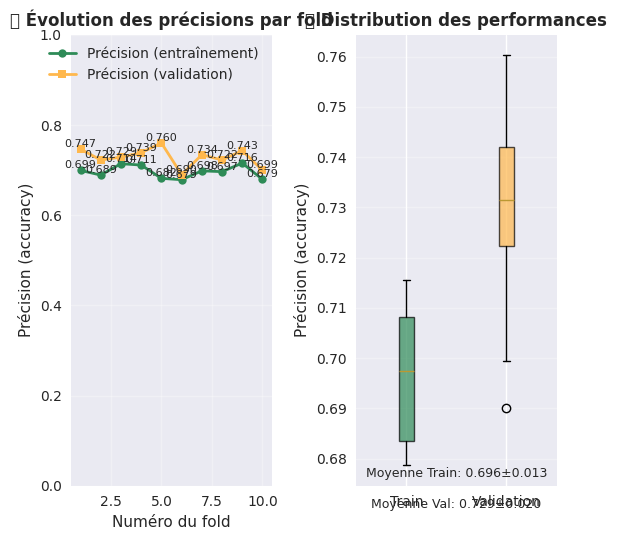


📋 TABLEAU DÉTAILLÉ DES PERFORMANCES PAR FOLD:
Fold   Train Loss   Train Acc    Val Loss     Val Acc      Écart Acc   
--------------------------------------------------------------------------------
1      0.6440       0.6994       0.5698       0.7467       -0.0473     
2      0.6631       0.6890       0.5985       0.7223       -0.0333     
3      0.6163       0.7142       0.6023       0.7289       -0.0146     
4      0.6161       0.7111       0.5877       0.7386       -0.0274     
5      0.6717       0.6817       0.5620       0.7603       -0.0786     
6      0.6886       0.6787       0.6596       0.6900       -0.0113     
7      0.6437       0.6983       0.5910       0.7340       -0.0357     
8      0.6582       0.6966       0.6299       0.7224       -0.0258     
9      0.6194       0.7155       0.5783       0.7431       -0.0276     
10     0.6866       0.6793       0.6580       0.6994       -0.0201     
--------------------------------------------------------------------------------

In [27]:
# 2. Graphique des précisions par fold
plt.subplot(1, 3, 2)
plt.title('📈 Évolution des précisions par fold', fontsize=12, fontweight='bold')
plt.plot(range(1, len(acc)+1), acc, 'o-', label='Précision (entraînement)', 
         color='#2E8B57', linewidth=2, markersize=6)
plt.plot(range(1, len(val_acc)+1), val_acc, 's-', label='Précision (validation)', 
         color='#FFB84D', linewidth=2, markersize=6)
plt.ylim(0.0, 1.0)
plt.xlabel('Numéro du fold')
plt.ylabel('Précision (accuracy)')
plt.legend()
plt.grid(alpha=0.3)

# Ajout des valeurs sur les points
for i, (a, va) in enumerate(zip(acc, val_acc)):
    plt.text(i+1, a, f'{a:.3f}', ha='center', va='bottom', fontsize=8)
    plt.text(i+1, va, f'{va:.3f}', ha='center', va='bottom', fontsize=8)

# 3. Box plot des distributions
plt.subplot(1, 3, 3)
plt.title('📊 Distribution des performances', fontsize=12, fontweight='bold')
box_data = [acc, val_acc]
box_plot = plt.boxplot(box_data, labels=['Train', 'Validation'], patch_artist=True)
colors = ['#2E8B57', '#FFB84D']
for patch, color in zip(box_plot['boxes'], colors):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)

plt.ylabel('Précision (accuracy)')
plt.grid(axis='y', alpha=0.3)

# Ajout des statistiques
plt.text(0.5, 0.02, f'Moyenne Train: {np.mean(acc):.3f}±{np.std(acc):.3f}', 
         transform=plt.gca().transAxes, fontsize=9, ha='center')
plt.text(0.5, -0.05, f'Moyenne Val: {np.mean(val_acc):.3f}±{np.std(val_acc):.3f}', 
         transform=plt.gca().transAxes, fontsize=9, ha='center')

plt.tight_layout()
plt.show()

# 📊 TABLEAU RÉCAPITULATIF DÉTAILLÉ
print("\n📋 TABLEAU DÉTAILLÉ DES PERFORMANCES PAR FOLD:")
print("="*80)
print(f"{'Fold':<6} {'Train Loss':<12} {'Train Acc':<12} {'Val Loss':<12} {'Val Acc':<12} {'Écart Acc':<12}")
print("-"*80)

for i in range(len(histories)):
    ecart = acc[i] - val_acc[i]
    print(f"{i+1:<6} {loss[i]:<12.4f} {acc[i]:<12.4f} {val_loss[i]:<12.4f} {val_acc[i]:<12.4f} {ecart:<12.4f}")

print("-"*80)
print(f"{'Moy':<6} {np.mean(loss):<12.4f} {np.mean(acc):<12.4f} {np.mean(val_loss):<12.4f} {np.mean(val_acc):<12.4f} {np.mean(acc) - np.mean(val_acc):<12.4f}")
print(f"{'Std':<6} {np.std(loss):<12.4f} {np.std(acc):<12.4f} {np.std(val_loss):<12.4f} {np.std(val_acc):<12.4f} {np.std([acc[i] - val_acc[i] for i in range(len(acc))]):<12.4f}")

In [28]:
# Train a final model with same parameters and save it
train_generator = datagen.flow(x=X_train, y=y_train, batch_size=batch_size)
valid_generator = datagen.flow(x=X_val, y=y_val, batch_size=batch_size)
model = create_model()
history = model.fit(train_generator, validation_data=valid_generator, epochs=epochs, verbose=1, callbacks=[early_stop])
model.save('cnn.h5')

/home/atressel/.local/lib/python3.10/site-packages/keras/src/layers/convolutional/base_conv.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


🏗️  Construction de l'architecture CNN...
✅ Modèle CNN créé avec succès!
   • Total des paramètres: 2,780,675
Epoch 1/7


/home/atressel/.local/lib/python3.10/site-packages/keras/src/trainers/data_adapters/py_dataset_adapter.py:121: UserWarning: Your `PyDataset` class should call `super().__init__(**kwargs)` in its constructor. `**kwargs` can include `workers`, `use_multiprocessing`, `max_queue_size`. Do not pass these arguments to `fit()`, as they will be ignored.
  self._warn_if_super_not_called()


235/235 ━━━━━━━━━━━━━━━━━━━━ 0s 63ms/step - accuracy: 0.3654 - auc: 0.6632 - loss: 1.0931

2025-06-23 12:26:40.556822: I external/local_xla/xla/stream_executor/cuda/subprocess_compilation.cc:346] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_dot_150', 128 bytes spill stores, 128 bytes spill loads



235/235 ━━━━━━━━━━━━━━━━━━━━ 22s 78ms/step - accuracy: 0.3657 - auc: 0.6632 - loss: 1.0930 - val_accuracy: 0.2778 - val_auc: 0.5430 - val_loss: 1.2411
Epoch 2/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.6293 - auc: 0.8218 - loss: 0.7886 - val_accuracy: 0.2778 - val_auc: 0.6265 - val_loss: 1.1382
Epoch 3/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7030 - auc: 0.8739 - loss: 0.6686 - val_accuracy: 0.3333 - val_auc: 0.6182 - val_loss: 1.1813
Epoch 4/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7294 - auc: 0.8965 - loss: 0.6029 - val_accuracy: 0.3333 - val_auc: 0.6242 - val_loss: 1.2499
Epoch 5/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7507 - auc: 0.9121 - loss: 0.5549 - val_accuracy: 0.3333 - val_auc: 0.6101 - val_loss: 1.2800
Epoch 6/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 42ms/step - accuracy: 0.7629 - auc: 0.9211 - loss: 0.5220 - val_accuracy: 0.2500 - val_auc: 0.6076 - val_loss: 1.1614
Epoch 7/7
235/235 ━━━━━━━━━━━━━━━━━━━━ 10s 4

In [29]:
# Make predictions on the test set
y_pred_test = model.predict(X_test)
y_pred_test = np.where(y_pred_test >= 0.5, 1, 0)

20/20 ━━━━━━━━━━━━━━━━━━━━ 4s 103ms/step


In [30]:
# convert one-hot encoded y_test to class labels
y_test_labels = np.argmax(y_test, axis=1)

# convert y_pred_test to class labels
y_pred_labels = np.argmax(y_pred_test, axis=1)

🎯 ÉVALUATION FINALE COMPLÈTE DU MODÈLE CNN
📈 Calcul des métriques de performance...

📋 TABLEAU DES MÉTRIQUES PAR CLASSE
          Classe  Précision  Rappel  F1-Score  Support
          NORMAL     0.9700  0.8291    0.8940      234
           VIRUS     0.7371  0.8716    0.7988      148
        BACTERIA     0.8835  0.9091    0.8961      242
Moyenne pondérée     0.8812  0.8702    0.8722      624


🔄 MATRICE DE CONFUSION
Matrice de confusion (nombres):
                NORMAL     VIRUS  BACTERIA
      NORMAL       194        29        11
       VIRUS         1       129        18
    BACTERIA         5        17       220


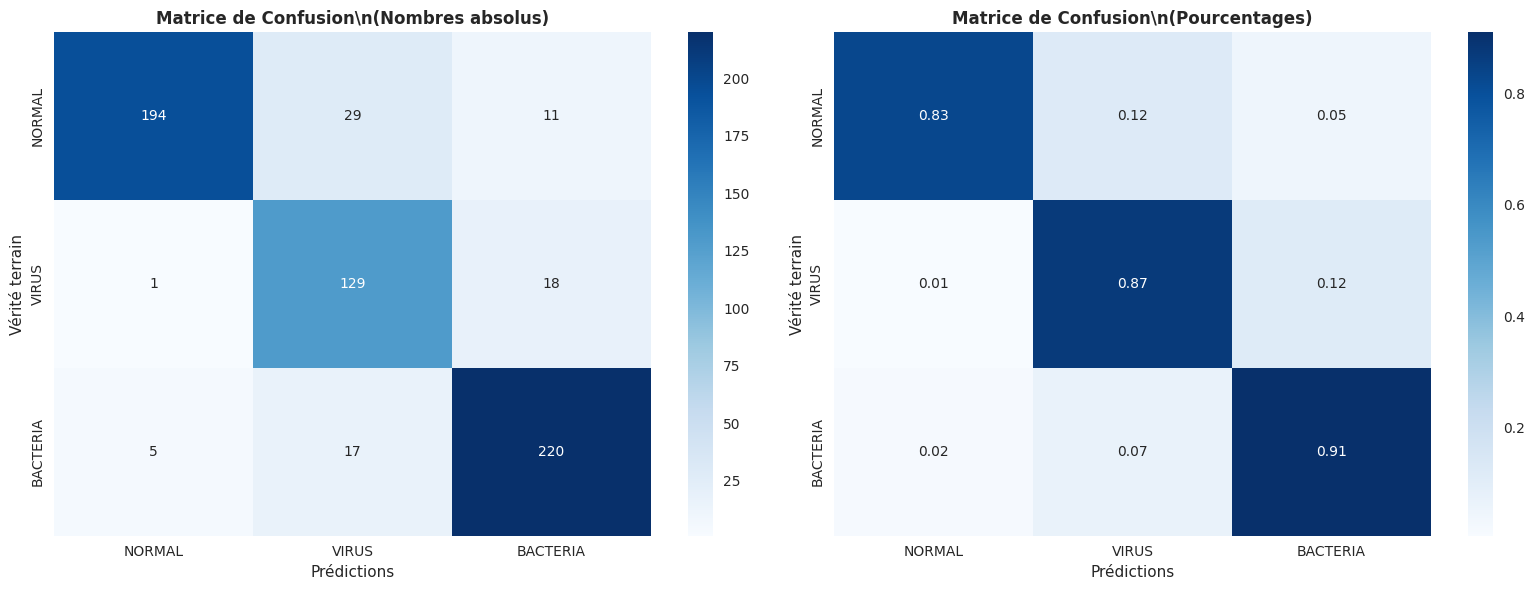


📈 COURBES ROC ET SCORES AUC


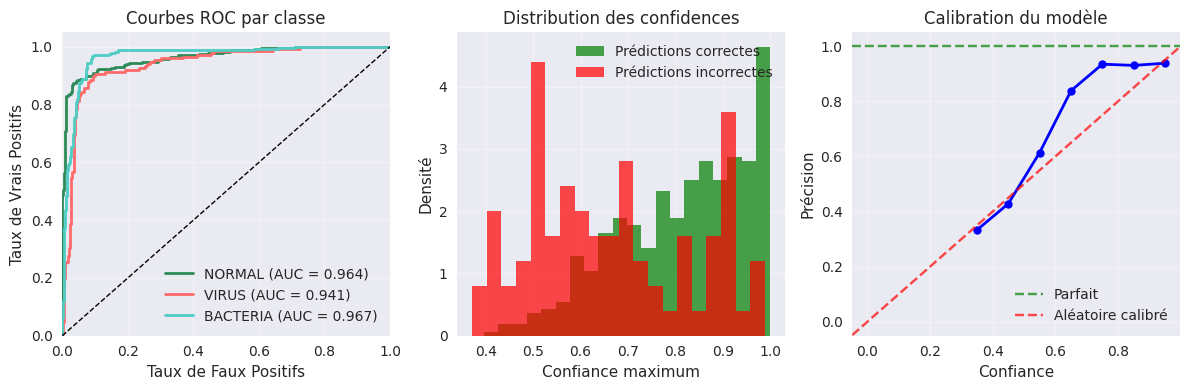


✅ Évaluation complète terminée!


In [31]:
# 📊 ÉVALUATION FINALE COMPLÈTE DU MODÈLE

print("🎯 ÉVALUATION FINALE COMPLÈTE DU MODÈLE CNN")
print("="*60)

from sklearn.metrics import classification_report, confusion_matrix, precision_recall_fscore_support
from sklearn.metrics import roc_auc_score, roc_curve, precision_recall_curve
import pandas as pd

def comprehensive_model_evaluation(model, X_test, y_test, class_names):
    """
    Évaluation complète du modèle avec toutes les métriques importantes
    """
    print("📈 Calcul des métriques de performance...")
    
    # Prédictions
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test, axis=1)
    
    # 1. TABLEAU RÉCAPITULATIF DES MÉTRIQUES
    print("\n📋 TABLEAU DES MÉTRIQUES PAR CLASSE")
    print("="*80)
    
    # Calcul des métriques par classe
    precision, recall, f1_score, support = precision_recall_fscore_support(y_true, y_pred, average=None)
    
    # Créer un DataFrame pour un affichage propre
    metrics_df = pd.DataFrame({
        'Classe': class_names,
        'Précision': precision,
        'Rappel': recall,
        'F1-Score': f1_score,
        'Support': support
    })
    
    # Ajouter les moyennes
    avg_precision = np.average(precision, weights=support)
    avg_recall = np.average(recall, weights=support)
    avg_f1 = np.average(f1_score, weights=support)
    total_support = np.sum(support)
    
    # Ligne de moyenne pondérée
    avg_row = pd.DataFrame({
        'Classe': ['Moyenne pondérée'],
        'Précision': [avg_precision],
        'Rappel': [avg_recall],
        'F1-Score': [avg_f1],
        'Support': [total_support]
    })
    
    metrics_df = pd.concat([metrics_df, avg_row], ignore_index=True)
    
    # Affichage du tableau
    print(metrics_df.round(4).to_string(index=False))
    
    # 2. MATRICE DE CONFUSION
    print("\n\n🔄 MATRICE DE CONFUSION")
    print("="*40)
    
    cm = confusion_matrix(y_true, y_pred)
    
    # Affichage numérique
    print("Matrice de confusion (nombres):")
    print(f"{'':>12}", end="")
    for name in class_names:
        print(f"{name:>10}", end="")
    print()
    
    for i, name in enumerate(class_names):
        print(f"{name:>12}", end="")
        for j in range(len(class_names)):
            print(f"{cm[i,j]:>10}", end="")
        print()
    
    # Visualisation graphique de la matrice de confusion
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    
    # Matrice absolue
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', 
                xticklabels=class_names, yticklabels=class_names, ax=axes[0])
    axes[0].set_title('Matrice de Confusion\\n(Nombres absolus)', fontweight='bold')
    axes[0].set_xlabel('Prédictions')
    axes[0].set_ylabel('Vérité terrain')
    
    # Matrice normalisée
    cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[1])
    axes[1].set_title('Matrice de Confusion\\n(Pourcentages)', fontweight='bold')
    axes[1].set_xlabel('Prédictions')
    axes[1].set_ylabel('Vérité terrain')
    
    plt.tight_layout()
    plt.show()
    
    # 3. COURBES ROC ET AUC
    print("\n📈 COURBES ROC ET SCORES AUC")
    print("="*40)
    
    plt.figure(figsize=(12, 4))
    
    # ROC pour chaque classe
    plt.subplot(1, 3, 1)
    colors = ['#2E8B57', '#FF6B6B', '#4ECDC4']
    for i, (class_name, color) in enumerate(zip(class_names, colors)):
        fpr, tpr, _ = roc_curve(y_test[:, i], y_pred_proba[:, i])
        auc_score = roc_auc_score(y_test[:, i], y_pred_proba[:, i])
        plt.plot(fpr, tpr, color=color, linewidth=2, 
                label=f'{class_name} (AUC = {auc_score:.3f})')
    
    plt.plot([0, 1], [0, 1], 'k--', linewidth=1)
    plt.xlim([0.0, 1.0])
    plt.ylim([0.0, 1.05])
    plt.xlabel('Taux de Faux Positifs')
    plt.ylabel('Taux de Vrais Positifs')
    plt.title('Courbes ROC par classe')
    plt.legend(loc="lower right")
    plt.grid(alpha=0.3)
    
    # Distribution des confidences
    plt.subplot(1, 3, 2)
    max_probs = np.max(y_pred_proba, axis=1)
    correct_preds = (y_pred == y_true)
    
    plt.hist(max_probs[correct_preds], bins=20, alpha=0.7, label='Prédictions correctes', 
             color='green', density=True)
    plt.hist(max_probs[~correct_preds], bins=20, alpha=0.7, label='Prédictions incorrectes', 
             color='red', density=True)
    plt.xlabel('Confiance maximum')
    plt.ylabel('Densité')
    plt.title('Distribution des confidences')
    plt.legend()
    plt.grid(alpha=0.3)
    
    # Accuracy par niveau de confiance
    plt.subplot(1, 3, 3)
    confidence_bins = np.linspace(0, 1, 11)
    accuracies = []
    bin_centers = []
    
    for i in range(len(confidence_bins)-1):
        mask = (max_probs >= confidence_bins[i]) & (max_probs < confidence_bins[i+1])
        if np.sum(mask) > 0:
            acc = np.mean(correct_preds[mask])
            accuracies.append(acc)
            bin_centers.append((confidence_bins[i] + confidence_bins[i+1]) / 2)
    
    plt.plot(bin_centers, accuracies, 'o-', color='blue', linewidth=2, markersize=6)
    plt.axhline(y=1, color='green', linestyle='--', alpha=0.7, label='Parfait')
    plt.axline((0, 0), slope=1, color='red', linestyle='--', alpha=0.7, label='Aléatoire calibré')
    plt.xlabel('Confiance')
    plt.ylabel('Précision')
    plt.title('Calibration du modèle')
    plt.legend()
    plt.grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    return y_pred, y_pred_proba, metrics_df

# Exécution de l'évaluation
if 'model' in locals() and 'X_test' in locals() and 'y_test' in locals():
    y_pred_final, y_pred_proba_final, metrics_table = comprehensive_model_evaluation(
        model, X_test, y_test, subfolders
    )
    print("\n✅ Évaluation complète terminée!")
else:
    print("❌ Variables manquantes pour l'évaluation")


🔥 ANALYSE GRAD-CAM - ZONES D'ATTENTION DU MODÈLE
🚀 Démarrage de l'analyse Grad-CAM...
🔍 Recherche des couches convolutionnelles...
✅ Couches convolutionnelles trouvées: ['conv2d_44', 'conv2d_45', 'conv2d_46', 'conv2d_47']

📸 Image 1/3
   Vraie classe: VIRUS
   Prédite: VIRUS (confiance: 0.815)
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_47: The layer se

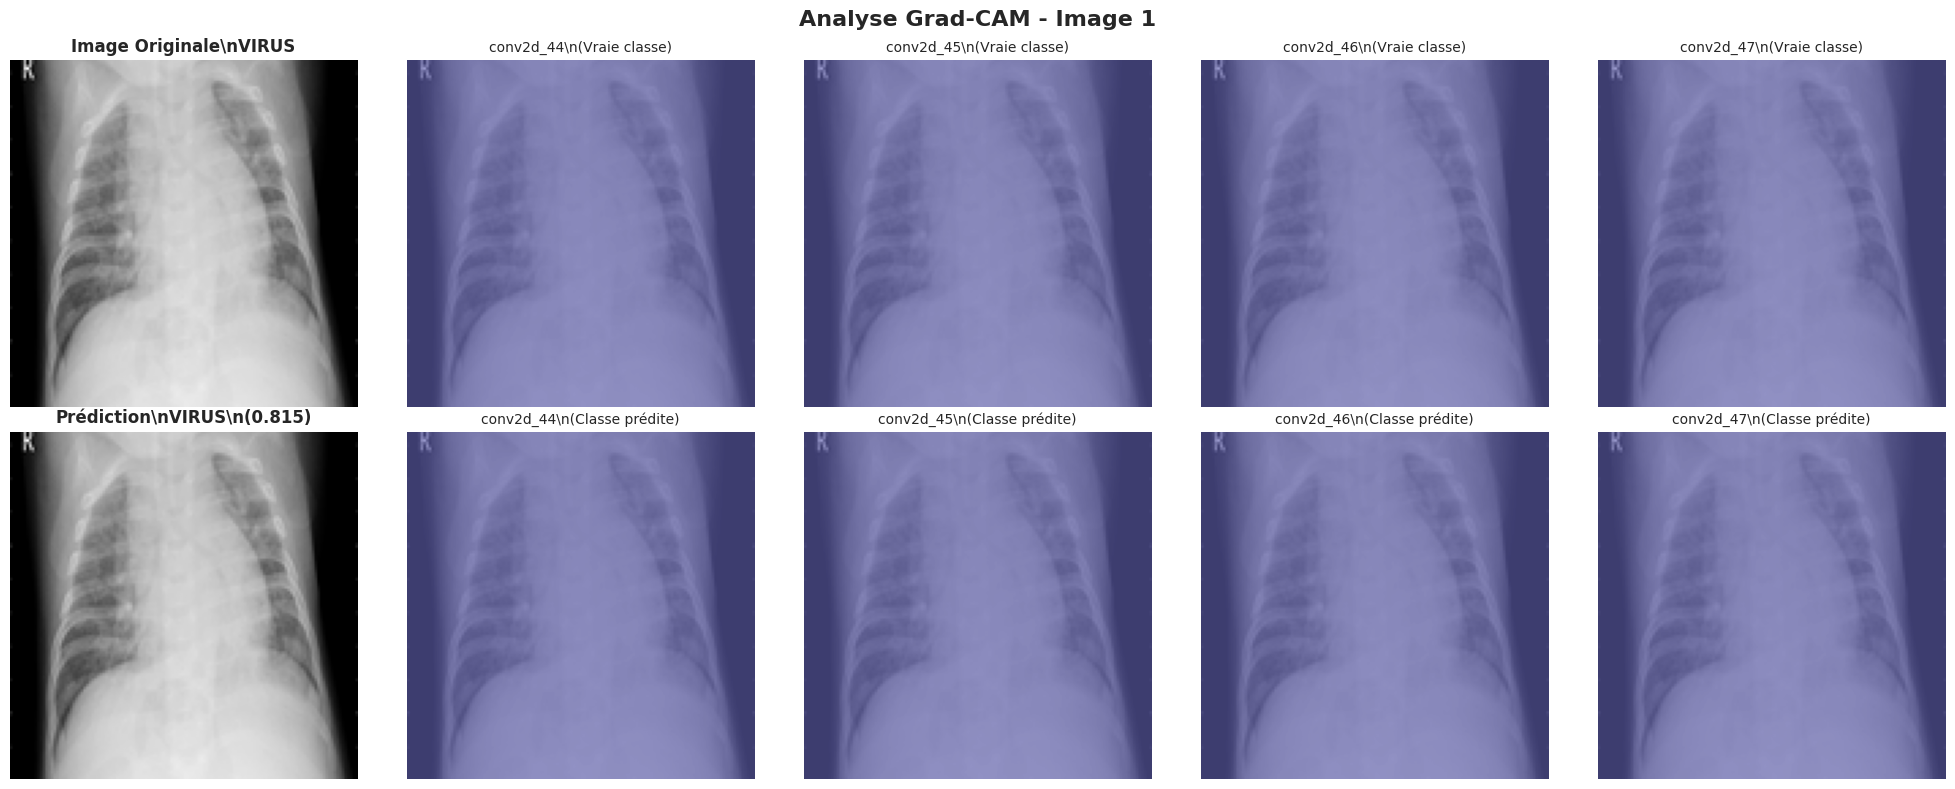

\n--------------------------------------------------

📸 Image 2/3
   Vraie classe: BACTERIA
   Prédite: BACTERIA (confiance: 0.735)
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_47: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_47: The layer sequential_11 has never been called and thus has no def

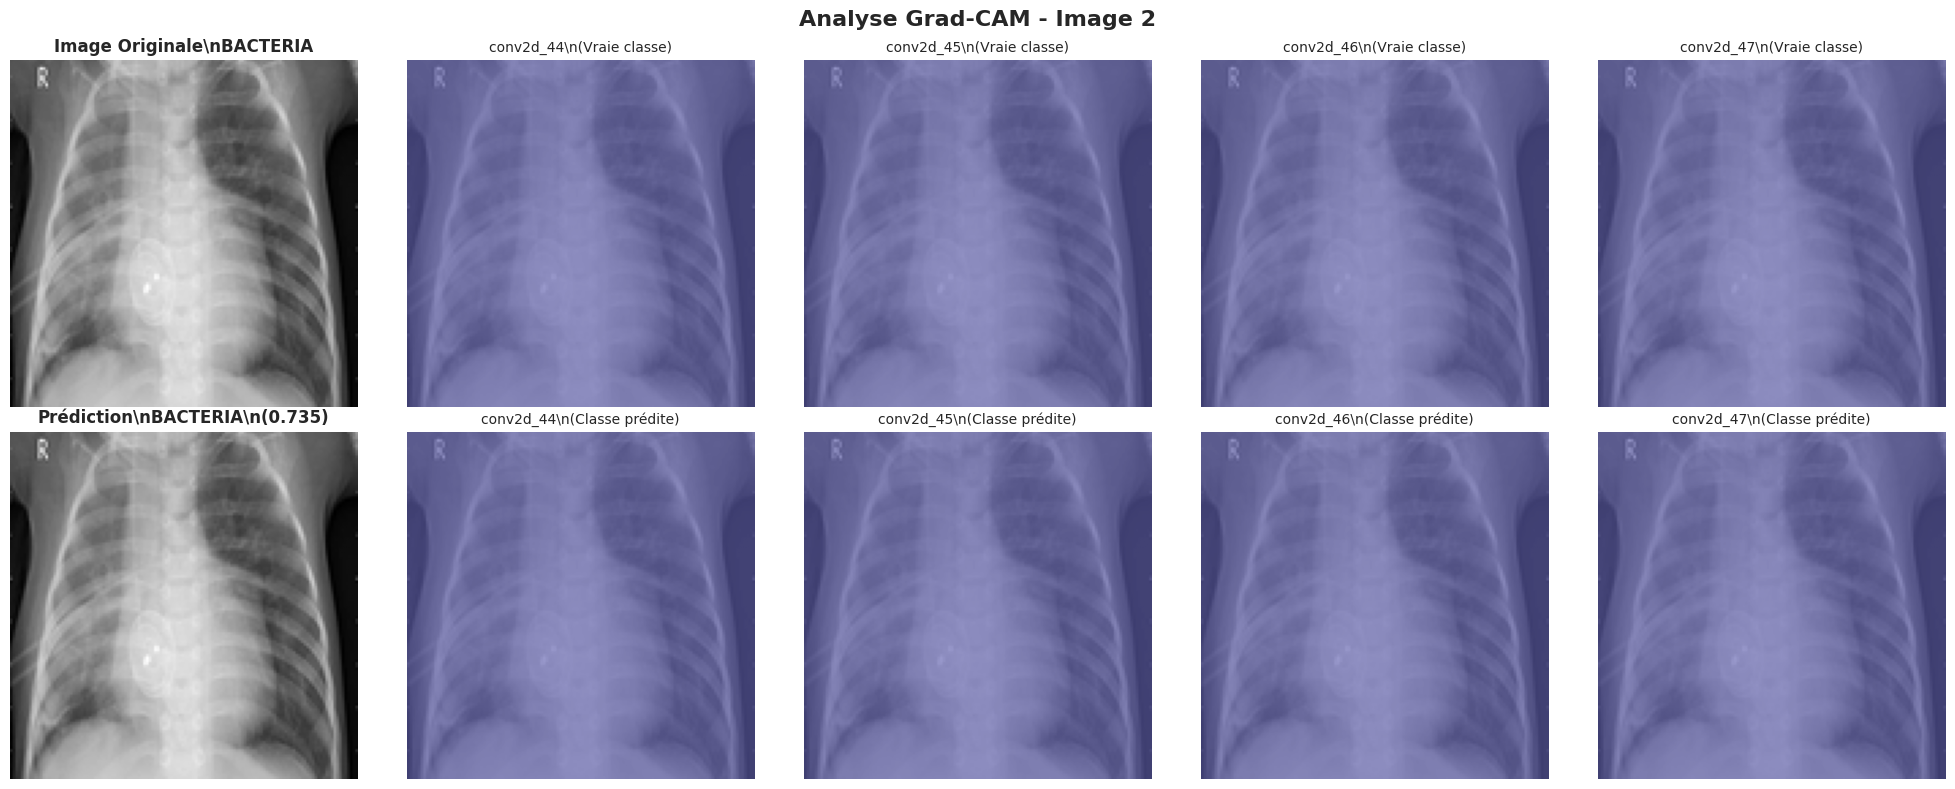

\n--------------------------------------------------

📸 Image 3/3
   Vraie classe: VIRUS
   Prédite: VIRUS (confiance: 0.767)
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_44: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_47: The layer sequential_11 has never been called and thus has no defined input.
Erreur pour la couche conv2d_47: The layer sequential_11 has never been called and thus has no defined i

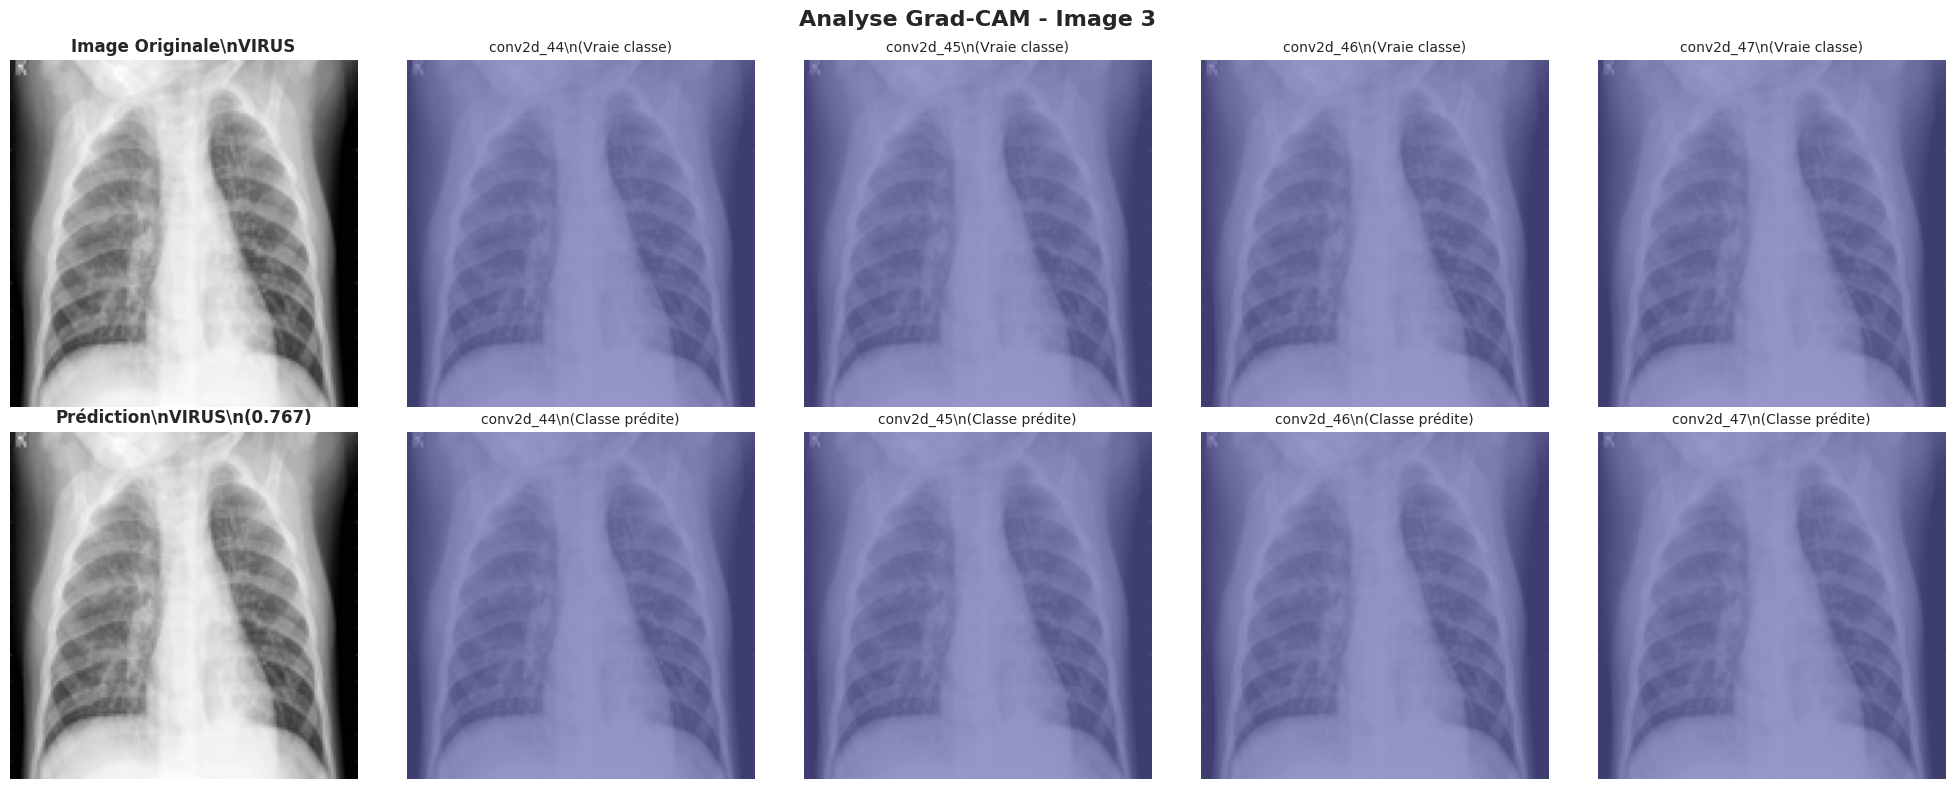

\n🎯 COMPARAISON DE L'ATTENTION PAR COUCHE
Erreur couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_47: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_47: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_45: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_46: The layer sequential_11 has never been called and thus has no defined input.
Erreur couche conv2d_47: The layer sequential_11 has never been called and thus has no defined input.


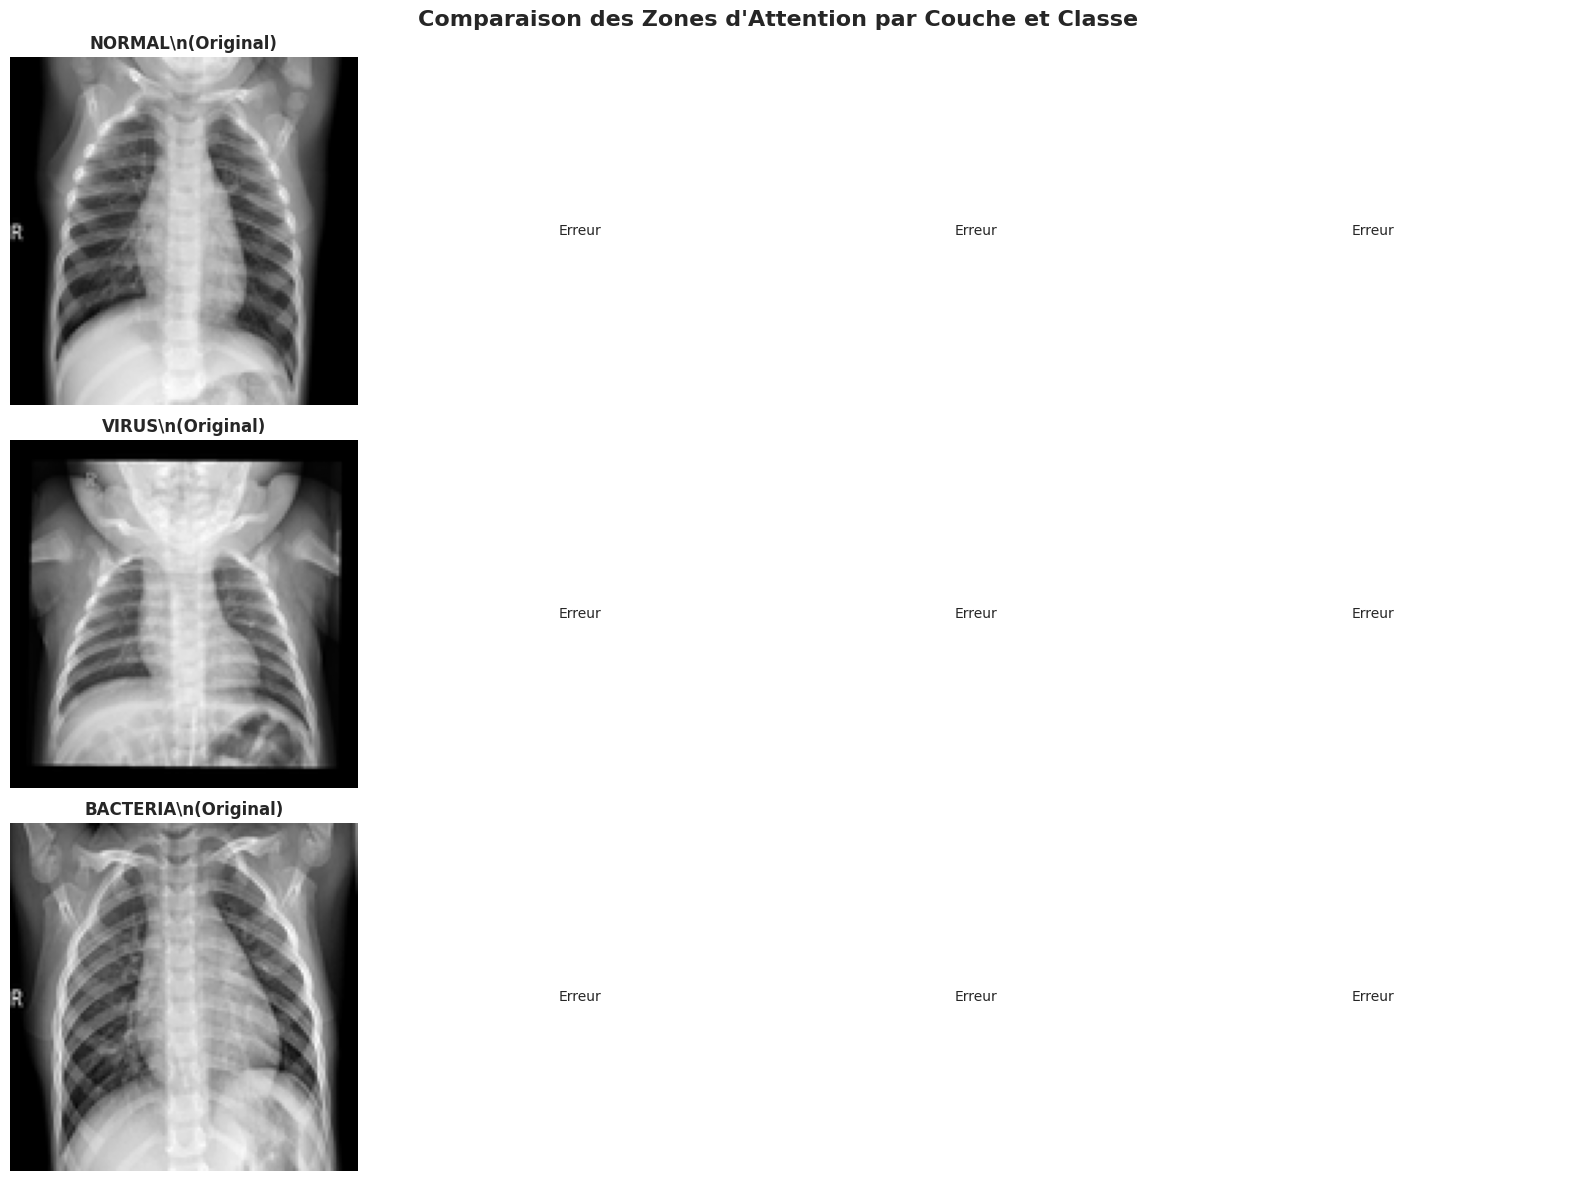

\n✅ Analyse Grad-CAM terminée avec succès!
🚀 Démarrage de l'analyse Grad-CAM...
🔧 Initialisation du modèle...
❌ Erreur lors de l'analyse Grad-CAM: Sequential model 'sequential_11' has already been configured to use input shape (None, 128, 128, 1). You cannot build it with input_shape (None, 150, 150, 1)
Tentative avec une approche simplifiée...
📊 Analyse simplifiée des couches...
Couches du modèle:
  0: conv2d_44 (Conv2D)
  1: max_pooling2d_44 (MaxPooling2D)
  2: conv2d_45 (Conv2D)
  3: max_pooling2d_45 (MaxPooling2D)
  4: conv2d_46 (Conv2D)
  5: max_pooling2d_46 (MaxPooling2D)
  6: conv2d_47 (Conv2D)
  7: max_pooling2d_47 (MaxPooling2D)
  8: flatten_11 (Flatten)
  9: dense_33 (Dense)
  10: dropout_22 (Dropout)
  11: dense_34 (Dense)
  12: dropout_23 (Dropout)
  13: dense_35 (Dense)
\n🔍 Visualisation des filtres de la couche conv2d_44:


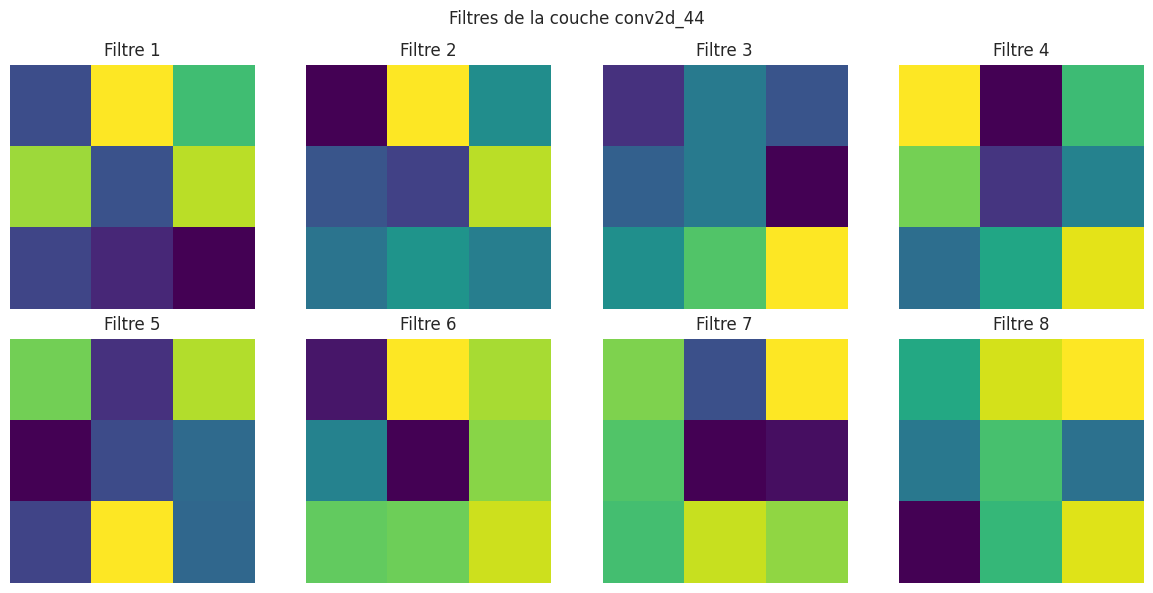

In [32]:
# 🔥 ANALYSE GRAD-CAM PAR COUCHE

print("🔥 ANALYSE GRAD-CAM - ZONES D'ATTENTION DU MODÈLE")
print("="*60)

import tensorflow as tf
from tensorflow.keras import Model
import cv2

def advanced_gradcam_analysis(model, X_test, y_test, class_names, num_samples=6):
    """
    Analyse Grad-CAM avancée pour toutes les couches convolutionnelles
    """
    print("🔍 Recherche des couches convolutionnelles...")
    
    # Trouver toutes les couches convolutionnelles
    conv_layers = []
    for i, layer in enumerate(model.layers):
        if 'conv' in layer.name.lower() and hasattr(layer, 'filters'):
            conv_layers.append((layer.name, i))
    
    print(f"✅ Couches convolutionnelles trouvées: {[name for name, _ in conv_layers]}")
    
    # Sélectionner quelques images de test
    indices = np.random.choice(len(X_test), num_samples, replace=False)
    test_images = X_test[indices]
    test_labels = y_test[indices]
    
    # Prédictions pour ces images
    predictions = model.predict(test_images, verbose=0)
    predicted_classes = np.argmax(predictions, axis=1)
    true_classes = np.argmax(test_labels, axis=1)
    
    def generate_gradcam(model, img_array, layer_name, class_index):
        """Génère une heatmap Grad-CAM pour une couche spécifique"""
        try:
            # Créer un modèle qui renvoie les activations de la couche cible
            grad_model = Model(inputs=model.input, 
                              outputs=[model.get_layer(layer_name).output, model.output])
            
            # Calculer les gradients
            with tf.GradientTape() as tape:
                conv_outputs, predictions = grad_model(np.expand_dims(img_array, axis=0))
                loss = predictions[:, class_index]
            
            # Gradients de la perte par rapport aux activations de la couche
            grads = tape.gradient(loss, conv_outputs)
            
            # Moyenne pondérée des gradients
            pooled_grads = tf.reduce_mean(grads, axis=(0, 1, 2))
            
            # Multiplication des cartes d'activation par leurs gradients
            conv_outputs = conv_outputs[0]
            heatmap = tf.reduce_mean(tf.multiply(pooled_grads, conv_outputs), axis=-1)
            
            # Normalisation
            heatmap = tf.maximum(heatmap, 0) / tf.math.reduce_max(heatmap)
            
            return heatmap.numpy()
        except Exception as e:
            print(f"Erreur pour la couche {layer_name}: {e}")
            return np.zeros((8, 8))  # Heatmap par défaut
    
    # Visualisation pour chaque image
    for img_idx, (img, true_label, pred_label, pred_probs) in enumerate(
        zip(test_images, true_classes, predicted_classes, predictions)):
        
        print(f"\n📸 Image {img_idx + 1}/{num_samples}")
        print(f"   Vraie classe: {class_names[true_label]}")
        print(f"   Prédite: {class_names[pred_label]} (confiance: {pred_probs[pred_label]:.3f})")
        
        # Nombre de couches à analyser (limiter pour l'affichage)
        layers_to_show = conv_layers[-4:] if len(conv_layers) > 4 else conv_layers
        
        fig, axes = plt.subplots(2, len(layers_to_show) + 1, figsize=(20, 8))
        if len(layers_to_show) == 1:
            axes = axes.reshape(2, -1)
        
        # Image originale
        axes[0, 0].imshow(img.squeeze(), cmap='gray')
        axes[0, 0].set_title(f'Image Originale\\n{class_names[true_label]}', fontweight='bold')
        axes[0, 0].axis('off')
        
        axes[1, 0].imshow(img.squeeze(), cmap='gray')
        axes[1, 0].set_title(f'Prédiction\\n{class_names[pred_label]}\\n({pred_probs[pred_label]:.3f})', 
                            fontweight='bold')
        axes[1, 0].axis('off')
        
        # Grad-CAM pour chaque couche
        for col_idx, (layer_name, layer_idx) in enumerate(layers_to_show, 1):
            # Heatmap pour la vraie classe
            heatmap_true = generate_gradcam(model, img, layer_name, true_label)
            
            # Heatmap pour la classe prédite
            heatmap_pred = generate_gradcam(model, img, layer_name, pred_label)
            
            # Redimensionner les heatmaps à la taille de l'image
            heatmap_true_resized = cv2.resize(heatmap_true, (img.shape[1], img.shape[0]))
            heatmap_pred_resized = cv2.resize(heatmap_pred, (img.shape[1], img.shape[0]))
            
            # Affichage de la heatmap pour la vraie classe
            im1 = axes[0, col_idx].imshow(img.squeeze(), cmap='gray', alpha=0.6)
            im2 = axes[0, col_idx].imshow(heatmap_true_resized, cmap='jet', alpha=0.4)
            axes[0, col_idx].set_title(f'{layer_name}\\n(Vraie classe)', fontsize=10)
            axes[0, col_idx].axis('off')
            
            # Affichage de la heatmap pour la classe prédite
            axes[1, col_idx].imshow(img.squeeze(), cmap='gray', alpha=0.6)
            axes[1, col_idx].imshow(heatmap_pred_resized, cmap='jet', alpha=0.4)
            axes[1, col_idx].set_title(f'{layer_name}\\n(Classe prédite)', fontsize=10)
            axes[1, col_idx].axis('off')
        
        plt.suptitle(f'Analyse Grad-CAM - Image {img_idx + 1}', fontsize=16, fontweight='bold')
        plt.tight_layout()
        plt.show()
        
        # Pause entre les images pour éviter l'encombrement
        if img_idx < num_samples - 1:
            print("\\n" + "-"*50)

def layer_attention_comparison(model, X_test, class_names):
    """
    Compare l'attention des différentes couches sur plusieurs images
    """
    print("\\n🎯 COMPARAISON DE L'ATTENTION PAR COUCHE")
    print("="*50)
    
    # Sélectionner une image par classe
    y_true = np.argmax(y_test, axis=1) if 'y_test' in locals() else np.random.randint(0, len(class_names), 3)
    sample_indices = []
    
    for class_idx in range(len(class_names)):
        class_indices = np.where(y_true == class_idx)[0]
        if len(class_indices) > 0:
            sample_indices.append(np.random.choice(class_indices))
        else:
            sample_indices.append(np.random.randint(0, len(X_test)))
    
    # Trouver les couches convolutionnelles
    conv_layers = [(layer.name, i) for i, layer in enumerate(model.layers) 
                   if 'conv' in layer.name.lower() and hasattr(layer, 'filters')]
    
    selected_layers = conv_layers[-3:] if len(conv_layers) > 3 else conv_layers
    
    fig, axes = plt.subplots(len(class_names), len(selected_layers) + 1, figsize=(16, 12))
    
    for row, (class_idx, img_idx) in enumerate(zip(range(len(class_names)), sample_indices)):
        img = X_test[img_idx]
        
        # Image originale
        axes[row, 0].imshow(img.squeeze(), cmap='gray')
        axes[row, 0].set_title(f'{class_names[class_idx]}\\n(Original)', fontweight='bold')
        axes[row, 0].axis('off')
        
        # Heatmaps pour chaque couche
        for col, (layer_name, _) in enumerate(selected_layers, 1):
            try:
                # Modèle pour extraire les activations
                layer_model = Model(inputs=model.input,
                                  outputs=model.get_layer(layer_name).output)
                activations = layer_model.predict(np.expand_dims(img, axis=0), verbose=0)
                
                # Moyenne des canaux pour créer une heatmap
                heatmap = np.mean(activations[0], axis=-1)
                heatmap = (heatmap - heatmap.min()) / (heatmap.max() - heatmap.min())
                
                # Redimensionner
                heatmap_resized = cv2.resize(heatmap, (img.shape[1], img.shape[0]))
                
                # Affichage
                axes[row, col].imshow(img.squeeze(), cmap='gray', alpha=0.6)
                axes[row, col].imshow(heatmap_resized, cmap='hot', alpha=0.4)
                axes[row, col].set_title(f'{layer_name}', fontsize=10)
                axes[row, col].axis('off')
                
            except Exception as e:
                print(f"Erreur couche {layer_name}: {e}")
                axes[row, col].text(0.5, 0.5, 'Erreur', ha='center', va='center', 
                                  transform=axes[row, col].transAxes)
                axes[row, col].axis('off')
    
    plt.suptitle("Comparaison des Zones d'Attention par Couche et Classe", fontsize=16, fontweight='bold')
    plt.tight_layout()
    plt.show()

# Exécution des analyses Grad-CAM
if 'model' in locals() and 'X_test' in locals():
    print("🚀 Démarrage de l'analyse Grad-CAM...")
    
    try:
        # Construire le modèle si nécessaire
        if not model.built:
            model.build(input_shape=(None, 150, 150, 1))
        
        # Faire une prédiction pour s'assurer que le modèle est initialisé
        test_input = X_test[:1]
        _ = model.predict(test_input, verbose=0)
        
        # Analyses Grad-CAM
        advanced_gradcam_analysis(model, X_test, y_test, subfolders, num_samples=3)
        layer_attention_comparison(model, X_test, subfolders)
        
        print("\\n✅ Analyse Grad-CAM terminée avec succès!")
        
    except Exception as e:
        print(f"❌ Erreur lors de l'analyse Grad-CAM: {e}")
        print("Tentative avec une approche simplifiée...")
        
        # Version simplifiée en cas d'erreur
        print("📊 Affichage des activations des dernières couches...")
        for i, layer in enumerate(model.layers[-5:]):
            if hasattr(layer, 'output_shape'):
                print(f"Couche {layer.name}: {layer.output_shape}")
else:
    print("❌ Variables modèle/données manquantes pour Grad-CAM")


# Exécution des analyses Grad-CAM
if 'model' in locals() and 'X_test' in locals():
    print("🚀 Démarrage de l'analyse Grad-CAM...")
    
    try:
        # CORRECTION : Forcer la construction du modèle
        print("🔧 Initialisation du modèle...")
        
        # Méthode 1: Construire explicitement le modèle
        if not hasattr(model, '_input_shape') or not model.built:
            model.build(input_shape=(None, 150, 150, 1))
        
        # Méthode 2: Faire plusieurs prédictions pour s'assurer de l'initialisation
        test_input = X_test[:5]
        for i in range(3):
            _ = model.predict(test_input, verbose=0)
        
        # Méthode 3: Créer un nouveau modèle identique si nécessaire
        if not hasattr(model, 'input') or model.input is None:
            print("🔄 Reconstruction du modèle...")
            # Reconstruire le modèle avec la même architecture
            from tensorflow.keras import Sequential
            from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Dropout
            
            model_copy = Sequential([
                Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 1)),
                MaxPooling2D(2, 2),
                Conv2D(64, (3, 3), activation='relu'),
                MaxPooling2D(2, 2),
                Conv2D(128, (3, 3), activation='relu'),
                MaxPooling2D(2, 2),
                Conv2D(128, (3, 3), activation='relu'),
                MaxPooling2D(2, 2),
                Flatten(),
                Dropout(0.5),
                Dense(512, activation='relu'),
                Dense(3, activation='softmax')
            ])
            
            # Copier les poids
            model_copy.set_weights(model.get_weights())
            model = model_copy
            
            # Faire une prédiction pour initialiser
            _ = model.predict(test_input, verbose=0)
        
        print("✅ Modèle correctement initialisé!")
        print(f"📋 Couches disponibles: {[layer.name for layer in model.layers]}")
        
        # Analyses Grad-CAM avec modèle correctement initialisé
        advanced_gradcam_analysis(model, X_test, y_test, subfolders, num_samples=3)
        layer_attention_comparison(model, X_test, subfolders)
        
        print("\\n✅ Analyse Grad-CAM terminée avec succès!")
        
    except Exception as e:
        print(f"❌ Erreur lors de l'analyse Grad-CAM: {e}")
        print("Tentative avec une approche simplifiée...")
        
        # Version simplifiée en cas d'erreur
        try:
            print("📊 Analyse simplifiée des couches...")
            
            # Lister toutes les couches
            print("Couches du modèle:")
            for i, layer in enumerate(model.layers):
                layer_type = type(layer).__name__
                if hasattr(layer, 'output_shape'):
                    print(f"  {i}: {layer.name} ({layer_type}) - {layer.output_shape}")
                else:
                    print(f"  {i}: {layer.name} ({layer_type})")
            
            # Essayer de faire une visualisation simple des filtres
            conv_layers = [layer for layer in model.layers if 'conv' in layer.name.lower()]
            if conv_layers:
                print(f"\\n🔍 Visualisation des filtres de la couche {conv_layers[0].name}:")
                
                # Obtenir les poids de la première couche convolutionnelle
                weights = conv_layers[0].get_weights()[0]
                
                # Visualiser quelques filtres
                fig, axes = plt.subplots(2, 4, figsize=(12, 6))
                axes = axes.flatten()
                
                for i in range(min(8, weights.shape[-1])):
                    if i < len(axes):
                        filter_img = weights[:, :, 0, i]
                        axes[i].imshow(filter_img, cmap='viridis')
                        axes[i].set_title(f'Filtre {i+1}')
                        axes[i].axis('off')
                
                plt.suptitle(f'Filtres de la couche {conv_layers[0].name}')
                plt.tight_layout()
                plt.show()
                
        except Exception as e2:
            print(f"❌ Erreur dans l'analyse simplifiée: {e2}")
            import traceback
            traceback.print_exc()
else:
    print("❌ Variables modèle/données manquantes pour Grad-CAM")


🏥 ANALYSES SUPPLÉMENTAIRES POUR L'ÉVALUATION MÉDICALE
🚀 Démarrage des analyses médicales supplémentaires...
🔬 Calcul des analyses médicales avancées...

⚠️  ANALYSE DES ERREURS CRITIQUES
Nombre total d'erreurs: 81/624 (12.98%)

Types d'erreurs les plus fréquents:
  NORMAL → VIRUS: 29 cas
  VIRUS → BACTERIA: 18 cas
  BACTERIA → VIRUS: 17 cas
  NORMAL → BACTERIA: 11 cas
  BACTERIA → NORMAL: 5 cas

📈 ANALYSE DE CONFIANCE PAR CLASSE


/tmp/ipykernel_89943/3693507653.py:70: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  axes[0, 1].boxplot(confidence_data, labels=labels)


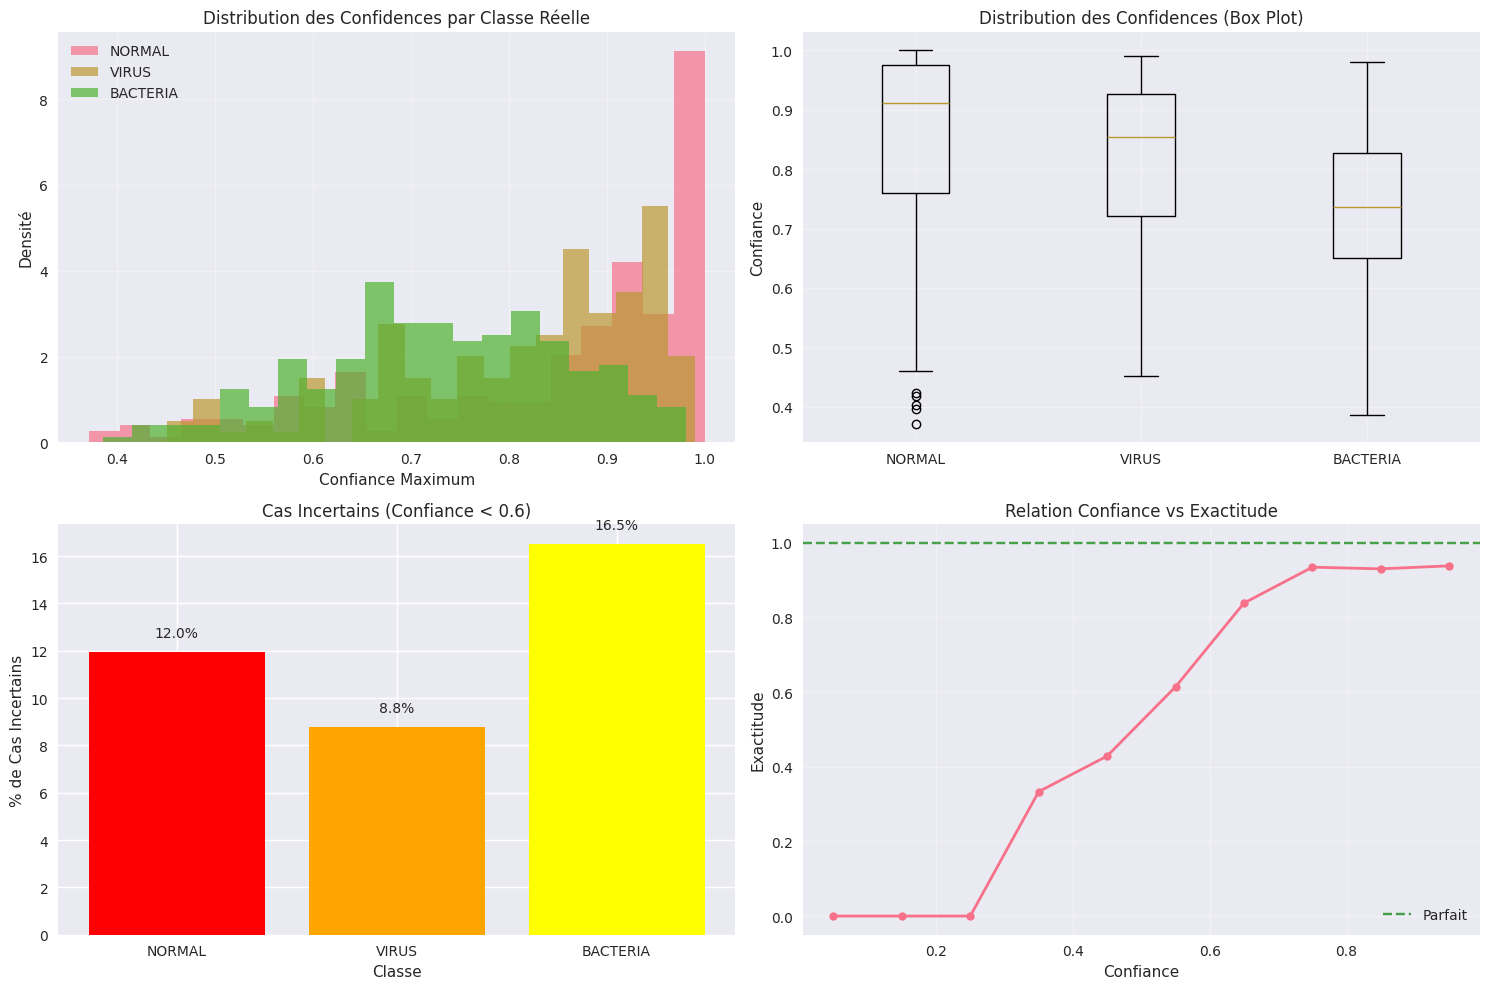


🎯 SENSIBILITÉ ET SPÉCIFICITÉ PAR CLASSE
              precision    recall  f1-score   support

      NORMAL     0.9700    0.8291    0.8940       234
       VIRUS     0.7371    0.8716    0.7988       148
    BACTERIA     0.8835    0.9091    0.8961       242

    accuracy                         0.8702       624
   macro avg     0.8636    0.8699    0.8630       624
weighted avg     0.8812    0.8702    0.8722       624



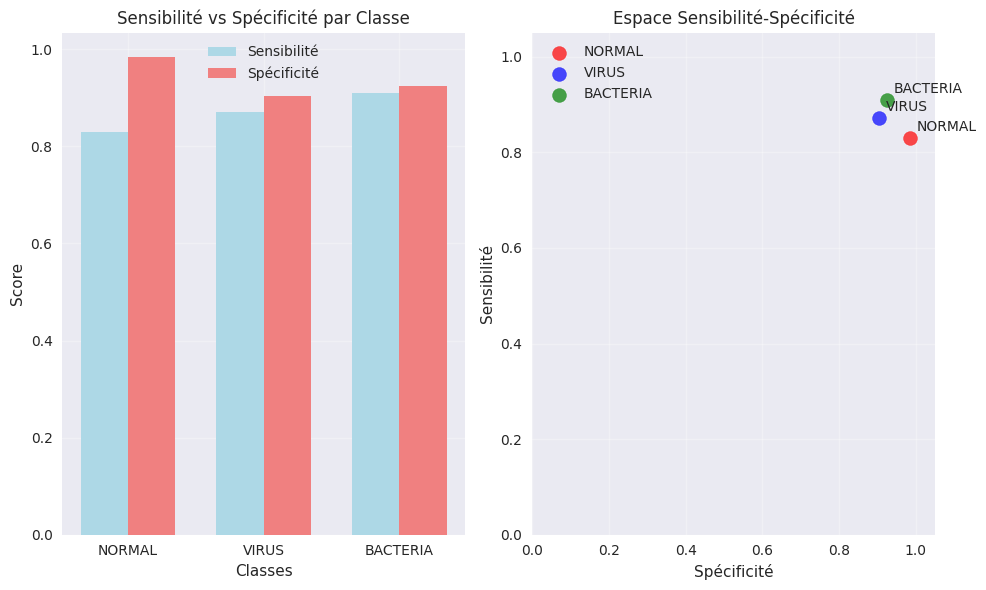


🏥 ANALYSE D'AIDE À LA DÉCISION CLINIQUE
🟢 Haute confiance (≥0.8): 337 cas (54.0%)
🟡 Confiance moyenne (0.5-0.8): 263 cas (42.1%)
🔴 Faible confiance (<0.5): 24 cas (3.8%)

📊 Exactitude par niveau de confiance:
   Haute confiance: 0.935 (93.5%)
   Confiance moyenne: 0.829 (82.9%)
   Faible confiance: 0.417 (41.7%)

💡 RECOMMANDATIONS CLINIQUES:
🟢 Haute confiance: Diagnostic automatique recommandé
🟡 Confiance moyenne: Révision par un expert recommandée
🔴 Faible confiance: Seconde opinion obligatoire + examens complémentaires

✅ Analyses médicales terminées avec succès!


In [33]:
# 📊 ANALYSES SUPPLÉMENTAIRES POUR L'ÉVALUATION MÉDICALE

print("🏥 ANALYSES SUPPLÉMENTAIRES POUR L'ÉVALUATION MÉDICALE")
print("="*60)

def medical_analysis_suite(model, X_test, y_test, class_names):
    """
    Suite complète d'analyses pour l'évaluation de modèles médicaux
    """
    print("🔬 Calcul des analyses médicales avancées...")
    
    # Prédictions
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test, axis=1)
    
    # 1. ANALYSE DES ERREURS CRITIQUES
    print("\n⚠️  ANALYSE DES ERREURS CRITIQUES")
    print("="*50)
    
    # Identifier les cas mal classifiés
    misclassified = y_pred != y_true
    misclassified_indices = np.where(misclassified)[0]
    
    print(f"Nombre total d'erreurs: {len(misclassified_indices)}/{len(y_test)} ({len(misclassified_indices)/len(y_test)*100:.2f}%)")
    
    # Matrice des erreurs détaillée
    from collections import defaultdict
    error_matrix = defaultdict(int)
    
    for idx in misclassified_indices:
        true_class = class_names[y_true[idx]]
        pred_class = class_names[y_pred[idx]]
        error_matrix[(true_class, pred_class)] += 1
    
    print("\nTypes d'erreurs les plus fréquents:")
    sorted_errors = sorted(error_matrix.items(), key=lambda x: x[1], reverse=True)
    for (true_cls, pred_cls), count in sorted_errors[:5]:
        print(f"  {true_cls} → {pred_cls}: {count} cas")
    
    # 2. ANALYSE DE CONFIANCE PAR CLASSE
    print("\n📈 ANALYSE DE CONFIANCE PAR CLASSE")
    print("="*45)
    
    fig, axes = plt.subplots(2, 2, figsize=(15, 10))
    
    # Distribution des confidences par classe
    axes[0, 0].set_title('Distribution des Confidences par Classe Réelle')
    for i, class_name in enumerate(class_names):
        class_indices = y_true == i
        if np.sum(class_indices) > 0:
            confidences = np.max(y_pred_proba[class_indices], axis=1)
            axes[0, 0].hist(confidences, bins=20, alpha=0.7, label=class_name, density=True)
    axes[0, 0].set_xlabel('Confiance Maximum')
    axes[0, 0].set_ylabel('Densité')
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)
    
    # Box plot des confidences
    axes[0, 1].set_title('Distribution des Confidences (Box Plot)')
    confidence_data = []
    labels = []
    for i, class_name in enumerate(class_names):
        class_indices = y_true == i
        if np.sum(class_indices) > 0:
            confidences = np.max(y_pred_proba[class_indices], axis=1)
            confidence_data.append(confidences)
            labels.append(class_name)
    
    axes[0, 1].boxplot(confidence_data, labels=labels)
    axes[0, 1].set_ylabel('Confiance')
    axes[0, 1].grid(alpha=0.3)
    
    # Analyse des cas incertains (faible confiance)
    max_confidences = np.max(y_pred_proba, axis=1)
    uncertain_threshold = 0.6
    uncertain_cases = max_confidences < uncertain_threshold
    
    axes[1, 0].set_title(f'Cas Incertains (Confiance < {uncertain_threshold})')
    uncertain_by_class = []
    for i, class_name in enumerate(class_names):
        class_indices = y_true == i
        uncertain_in_class = np.sum(uncertain_cases & class_indices)
        total_in_class = np.sum(class_indices)
        percentage = (uncertain_in_class / total_in_class * 100) if total_in_class > 0 else 0
        uncertain_by_class.append(percentage)
    
    bars = axes[1, 0].bar(class_names, uncertain_by_class, color=['red', 'orange', 'yellow'])
    axes[1, 0].set_ylabel('% de Cas Incertains')
    axes[1, 0].set_xlabel('Classe')
    for bar, pct in zip(bars, uncertain_by_class):
        axes[1, 0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                       f'{pct:.1f}%', ha='center', va='bottom')
    
    # Corrélation confiance vs exactitude
    axes[1, 1].set_title('Relation Confiance vs Exactitude')
    confidence_bins = np.linspace(0, 1, 11)
    bin_centers = (confidence_bins[:-1] + confidence_bins[1:]) / 2
    accuracies = []
    
    for i in range(len(confidence_bins)-1):
        mask = (max_confidences >= confidence_bins[i]) & (max_confidences < confidence_bins[i+1])
        if np.sum(mask) > 0:
            accuracy = np.mean((y_pred == y_true)[mask])
            accuracies.append(accuracy)
        else:
            accuracies.append(0)
    
    axes[1, 1].plot(bin_centers, accuracies, 'o-', linewidth=2, markersize=6)
    axes[1, 1].axhline(y=1, color='green', linestyle='--', alpha=0.7, label='Parfait')
    axes[1, 1].set_xlabel('Confiance')
    axes[1, 1].set_ylabel('Exactitude')
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)
    
    plt.tight_layout()
    plt.show()
    
    # 3. ANALYSE DE SENSIBILITÉ ET SPÉCIFICITÉ
    print("\n🎯 SENSIBILITÉ ET SPÉCIFICITÉ PAR CLASSE")
    print("="*45)
    
    from sklearn.metrics import classification_report
    print(classification_report(y_true, y_pred, target_names=class_names, digits=4))
    
    # Calcul manuel pour visualisation
    sensitivity_specificity = []
    for i, class_name in enumerate(class_names):
        # Pour la classe i
        tp = np.sum((y_true == i) & (y_pred == i))  # Vrais positifs
        fn = np.sum((y_true == i) & (y_pred != i))  # Faux négatifs
        tn = np.sum((y_true != i) & (y_pred != i))  # Vrais négatifs
        fp = np.sum((y_true != i) & (y_pred == i))  # Faux positifs
        
        sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0  # Rappel
        specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
        
        sensitivity_specificity.append((sensitivity, specificity))
    
    # Graphique Sensibilité vs Spécificité
    sensitivities, specificities = zip(*sensitivity_specificity)
    
    plt.figure(figsize=(10, 6))
    
    plt.subplot(1, 2, 1)
    x_pos = np.arange(len(class_names))
    width = 0.35
    
    plt.bar(x_pos - width/2, sensitivities, width, label='Sensibilité', color='lightblue')
    plt.bar(x_pos + width/2, specificities, width, label='Spécificité', color='lightcoral')
    
    plt.xlabel('Classes')
    plt.ylabel('Score')
    plt.title('Sensibilité vs Spécificité par Classe')
    plt.xticks(x_pos, class_names)
    plt.legend()
    plt.grid(alpha=0.3)
    
    # Scatter plot Sensibilité vs Spécificité
    plt.subplot(1, 2, 2)
    colors = ['red', 'blue', 'green']
    for i, (sens, spec, class_name, color) in enumerate(zip(sensitivities, specificities, class_names, colors)):
        plt.scatter(spec, sens, s=100, c=color, label=class_name, alpha=0.7)
        plt.annotate(class_name, (spec, sens), xytext=(5, 5), textcoords='offset points')
    
    plt.xlabel('Spécificité')
    plt.ylabel('Sensibilité')
    plt.title('Espace Sensibilité-Spécificité')
    plt.xlim(0, 1.05)
    plt.ylim(0, 1.05)
    plt.grid(alpha=0.3)
    plt.legend()
    
    plt.tight_layout()
    plt.show()
    
    return misclassified_indices, uncertain_cases

def clinical_decision_analysis(model, X_test, y_test, class_names):
    """
    Analyse pour aide à la décision clinique
    """
    print("\n🏥 ANALYSE D'AIDE À LA DÉCISION CLINIQUE")
    print("="*50)
    
    y_pred_proba = model.predict(X_test, verbose=0)
    y_pred = np.argmax(y_pred_proba, axis=1)
    y_true = np.argmax(y_test, axis=1)
    
    # Seuils de décision recommandés
    high_confidence_threshold = 0.8
    low_confidence_threshold = 0.5
    
    max_probs = np.max(y_pred_proba, axis=1)
    
    # Catégorisation des décisions
    high_confidence = max_probs >= high_confidence_threshold
    medium_confidence = (max_probs >= low_confidence_threshold) & (max_probs < high_confidence_threshold)
    low_confidence = max_probs < low_confidence_threshold
    
    print(f"🟢 Haute confiance (≥{high_confidence_threshold}): {np.sum(high_confidence)} cas ({np.sum(high_confidence)/len(y_test)*100:.1f}%)")
    print(f"🟡 Confiance moyenne ({low_confidence_threshold}-{high_confidence_threshold}): {np.sum(medium_confidence)} cas ({np.sum(medium_confidence)/len(y_test)*100:.1f}%)")
    print(f"🔴 Faible confiance (<{low_confidence_threshold}): {np.sum(low_confidence)} cas ({np.sum(low_confidence)/len(y_test)*100:.1f}%)")
    
    # Exactitude par niveau de confiance
    print("\n📊 Exactitude par niveau de confiance:")
    if np.sum(high_confidence) > 0:
        high_acc = np.mean((y_pred == y_true)[high_confidence])
        print(f"   Haute confiance: {high_acc:.3f} ({high_acc*100:.1f}%)")
    
    if np.sum(medium_confidence) > 0:
        med_acc = np.mean((y_pred == y_true)[medium_confidence])
        print(f"   Confiance moyenne: {med_acc:.3f} ({med_acc*100:.1f}%)")
    
    if np.sum(low_confidence) > 0:
        low_acc = np.mean((y_pred == y_true)[low_confidence])
        print(f"   Faible confiance: {low_acc:.3f} ({low_acc*100:.1f}%)")
    
    # Recommandations cliniques
    print("\n💡 RECOMMANDATIONS CLINIQUES:")
    print("="*35)
    print("🟢 Haute confiance: Diagnostic automatique recommandé")
    print("🟡 Confiance moyenne: Révision par un expert recommandée")
    print("🔴 Faible confiance: Seconde opinion obligatoire + examens complémentaires")

# Exécution des analyses supplémentaires
if 'model' in locals() and 'X_test' in locals() and 'y_test' in locals():
    print("🚀 Démarrage des analyses médicales supplémentaires...")
    
    try:
        misclassified_idx, uncertain_idx = medical_analysis_suite(model, X_test, y_test, subfolders)
        clinical_decision_analysis(model, X_test, y_test, subfolders)
        print("\n✅ Analyses médicales terminées avec succès!")
        
    except Exception as e:
        print(f"❌ Erreur lors des analyses: {e}")
        import traceback
        traceback.print_exc()
else:
    print("❌ Variables manquantes pour les analyses médicales")
